# Exploratory Data Analysis and Visualization of a Real-World Dataset: Customer Churn Prediction
**Course:** U21ADP05 - Exploratory Data Analysis and Visualization (Assignment II)  
**Student:** Navin J | **Roll No:** 24AD071 | III Year (V Sem), Dept. of Artificial Intelligence and Data Science  
**Institution:** KPR Institute of Engineering and Technology, Coimbatore  
**Course Coordinator:** Mr. Rushikesh Kadam | **Batch:** 2023-2027  
**Dataset:** Telco Customer Churn (IBM Sample Dataset / Kaggle, 7,043 rows, 21 features)  
**GitHub Repository:** [navin2425/eda-visualization-case-study](https://github.com/navin2425/eda-visualization-case-study)

---

## Executive Summary
This notebook demonstrates an end-to-end exploratory data analysis, statistical modeling, data visualization across the 7 stages of visualization, and deep learning classification on the Telco Customer Churn dataset.

### Notebook Organization:
1. **Section 1: Data Loading & Initial Inspection**
2. **Section 2: Exploratory Data Analysis (EDA) & Statistical Hypothesis Testing**
3. **Section 3: Data Cleaning, Preprocessing & Feature Engineering**
4. **Section 4: Data Visualization (All 7 Stages of Visualization)**
5. **Section 5: Deep Learning Model Creation & Hyperparameter Tuning**
6. **Section 6: Model Evaluation, Diagnostics & Business Recommendations**


In [1]:
import os
import sys
import json
import random
import warnings
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve
)
from sklearn.inspection import permutation_importance

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

warnings.filterwarnings('ignore')
os.environ['MPLCONFIGDIR'] = os.path.abspath('outputs/.matplotlib' if os.path.exists('outputs') else '../outputs/.matplotlib')
os.makedirs(os.environ['MPLCONFIGDIR'], exist_ok=True)
base_dir = '.' if os.path.exists('data') else '..'
figures_dir = os.path.join(base_dir, 'outputs', 'figures')
outputs_dir = os.path.join(base_dir, 'outputs')
data_path = os.path.join(base_dir, 'data', 'Telco-Customer-Churn.csv')

# Set random seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Libraries imported successfully. Environment initialized.")


Libraries imported successfully. Environment initialized.


---
## Section 1: Data Loading & Initial Inspection
In this section, we load the raw Telco Customer Churn dataset, verify its shape (7,043 rows, 21 columns), inspect data types, inspect missing/blank fields, and display initial samples.


In [2]:
# Load raw dataset
df_raw = pd.read_csv(data_path)
print(f"Dataset Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
print(f"Column Names:\n{list(df_raw.columns)}")
display(df_raw.head())


Dataset Shape: 7043 rows, 21 columns
Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Data Types and Non-Null Counts
print("=== DataFrame Info ===")
df_raw.info()

print("\n=== Missing & Blank Value Detection ===")
null_counts = df_raw.isnull().sum()
blank_counts = (df_raw.astype(str).apply(lambda col: col.str.strip() == '')).sum()
missing_summary = pd.DataFrame({'Null Count': null_counts, 'Blank String Count': blank_counts})
display(missing_summary[missing_summary['Blank String Count'] > 0])


=== DataFrame Info ===
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-nul

,Null Count,Blank String Count
TotalCharges,0,11


---
## Section 2: Exploratory Data Analysis & Statistical Hypothesis Testing
Here we examine the statistical moments (mean, standard deviation, median, IQR, skewness, and kurtosis) of numerical attributes, conduct parametric distribution fitting, and perform formal hypothesis tests (Pearson Chi-Square test with Cramér's V, Welch's t-test, Mann-Whitney U test, and Point-Biserial correlation).


In [4]:
# Clean TotalCharges for statistical exploration
df_eda = df_raw.copy()
df_eda['TotalCharges'] = pd.to_numeric(df_eda['TotalCharges'].replace(' ', '0'), errors='coerce')
df_eda['Churn_binary'] = (df_eda['Churn'] == 'Yes').astype(int)

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
stats_rows = []
for col in num_cols:
    s = df_eda[col]
    stats_rows.append({
        'Feature': col,
        'Count': int(s.count()),
        'Mean': round(s.mean(), 2),
        'Std Dev': round(s.std(), 2),
        'Median': round(s.median(), 2),
        'IQR': round(s.quantile(0.75) - s.quantile(0.25), 2),
        'Min': round(s.min(), 2),
        'Max': round(s.max(), 2),
        'Skewness': round(s.skew(), 3),
        'Kurtosis': round(s.kurtosis(), 3)
    })
stats_df = pd.DataFrame(stats_rows)
display(stats_df)


,Feature,Count,Mean,Std Dev,Median,IQR,Min,Max,Skewness,Kurtosis
0,tenure,7043,32.37,24.56,29.00,46.00,0.00,72.00,0.240,-1.387
1,MonthlyCharges,7043,64.76,30.09,70.35,54.35,18.25,118.75,-0.221,-1.257
2,TotalCharges,7043,2279.73,2266.79,1394.55,3388.05,0.00,8684.80,0.963,-0.229


In [5]:
# Hypothesis Testing: Pearson Chi-Square Test of Independence for Categorical Variables vs Churn
cat_cols = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 
            'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 
            'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 
            'Contract', 'PaperlessBilling', 'PaymentMethod']

chi2_rows = []
for col in cat_cols:
    ct = pd.crosstab(df_eda[col], df_eda['Churn'])
    chi2, p_val, dof, _ = stats.chi2_contingency(ct)
    n = ct.values.sum()
    r, k = ct.shape
    cramers_v = np.sqrt(chi2 / (n * min(r - 1, k - 1)))
    chi2_rows.append({
        'Categorical Feature': col,
        'Chi-Square Stat': round(chi2, 2),
        'p-value': f"{p_val:.2e}",
        'Degrees of Freedom': dof,
        "Cramer's V": round(cramers_v, 4),
        'Statistically Significant (α=0.01)': p_val < 0.01
    })

chi2_df = pd.DataFrame(chi2_rows).sort_values(by="Cramer's V", ascending=False)
display(chi2_df)


,Categorical Feature,Chi-Square Stat,p-value,Degrees of Freedom,Cramer's V,Statistically Significant (α=0.01)
13,Contract,1184.60,5.86e-258,2,0.4101,True
7,OnlineSecurity,850.00,2.66e-185,2,0.3474,True
10,TechSupport,828.20,1.44e-180,2,0.3429,True
6,InternetService,732.31,9.57e-160,2,0.3225,True
15,PaymentMethod,648.14,3.68e-140,3,0.3034,True
8,OnlineBackup,601.81,2.08e-131,2,0.2923,True
9,DeviceProtection,558.42,5.51e-122,2,0.2816,True
12,StreamingMovies,375.66,2.67e-82,2,0.2310,True
11,StreamingTV,374.20,5.53e-82,2,0.2305,True
14,PaperlessBilling,258.28,4.07e-58,1,0.1915,True


In [6]:
# Hypothesis Testing: Continuous Attributes vs Churn (Welch's t-test, Mann-Whitney U, Point-Biserial r)
ttest_rows = []
for col in num_cols:
    churn_g = df_eda[df_eda['Churn'] == 'Yes'][col]
    nochurn_g = df_eda[df_eda['Churn'] == 'No'][col]
    t_stat, p_val = stats.ttest_ind(churn_g, nochurn_g, equal_var=False)
    mw_stat, mw_p = stats.mannwhitneyu(churn_g, nochurn_g)
    pb_r, pb_p = stats.pointbiserialr(df_eda['Churn_binary'], df_eda[col])
    ttest_rows.append({
        'Numerical Feature': col,
        'Mean (Churn=Yes)': round(churn_g.mean(), 2),
        'Mean (Churn=No)': round(nochurn_g.mean(), 2),
        'Welch t-stat': round(t_stat, 2),
        't-test p-value': f"{p_val:.2e}",
        'Mann-Whitney U': round(mw_stat, 1),
        'MW-U p-value': f"{mw_p:.2e}",
        'Point-Biserial r': round(pb_r, 4)
    })
ttest_df = pd.DataFrame(ttest_rows)
display(ttest_df)


,Numerical Feature,Mean (Churn=Yes),Mean (Churn=No),Welch t-stat,t-test p-value,Mann-Whitney U,MW-U p-value,Point-Biserial r
0,tenure,17.98,37.57,-34.82,1.20e-232,2515538.0,2.42e-208,-0.3522
1,MonthlyCharges,74.44,61.27,18.41,8.59e-73,6003125.5,3.31e-54,0.1934
2,TotalCharges,1531.80,2549.91,-18.71,5.90e-75,3381224.0,5.69e-83,-0.1983


---
## Section 3: Data Cleaning, Preprocessing & Feature Engineering
In this section, we:
1. Handle the 11 blank TotalCharges values by imputing 0.0 (justified as brand-new customers with tenure = 0 months).
2. Engineer useful derived features:
   - `tenure_cohort`: 5-bin categorical lifecycle segments (`0-12 Mo`, `13-24 Mo`, `25-48 Mo`, `49-60 Mo`, `61-72 Mo`).
   - `services_count`: Count of subscribed value-added services (0 to 6).
   - `family_stability`: Indicator for having both partner and dependents.
   - `charge_ratio`: Ratio of monthly charges to total charges.
   - `is_month_to_month`: Direct binary flag for month-to-month contracts.
   - `streaming_bundle`: Indicator for customers subscribing to both streaming TV and movies.
3. Split the data into stratified 70% train, 15% validation, and 15% test partitions.
4. Scale continuous features using `StandardScaler` (fit **strictly** on the training set).
5. One-hot encode categorical features (fit **strictly** on the training set).


In [7]:
# Preprocessing & Feature Engineering
df_proc = df_raw.copy()
df_proc['TotalCharges'] = pd.to_numeric(df_proc['TotalCharges'].replace(' ', '0'), errors='coerce').fillna(0.0)
df_proc['Churn_binary'] = (df_proc['Churn'] == 'Yes').astype(int)

# 1. Tenure cohort
df_proc['tenure_cohort'] = pd.cut(
    df_proc['tenure'],
    bins=[-1, 12, 24, 48, 60, 73],
    labels=['0-12 Mo', '13-24 Mo', '25-48 Mo', '49-60 Mo', '61-72 Mo']
)

# 2. Add-on services count
addon_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
df_proc['services_count'] = (df_proc[addon_cols] == 'Yes').sum(axis=1)

# 3. Family stability
df_proc['family_stability'] = ((df_proc['Partner'] == 'Yes') & (df_proc['Dependents'] == 'Yes')).astype(int)

# 4. Charge ratio
df_proc['charge_ratio'] = df_proc['MonthlyCharges'] / (df_proc['TotalCharges'] + 1.0)

# 5. Month-to-month contract flag
df_proc['is_month_to_month'] = (df_proc['Contract'] == 'Month-to-month').astype(int)

# 6. Streaming bundle flag
df_proc['streaming_bundle'] = ((df_proc['StreamingTV'] == 'Yes') & (df_proc['StreamingMovies'] == 'Yes')).astype(int)

print(f"Preprocessed DataFrame Shape: {df_proc.shape}")
display(df_proc[['customerID', 'tenure', 'tenure_cohort', 'services_count', 'family_stability', 'is_month_to_month', 'Churn_binary']].head())


Preprocessed DataFrame Shape: (7043, 28)


,customerID,tenure,tenure_cohort,services_count,family_stability,is_month_to_month,Churn_binary
0,7590-VHVEG,1,0-12 Mo,1,0,1,0
1,5575-GNVDE,34,25-48 Mo,2,0,0,0
2,3668-QPYBK,2,0-12 Mo,2,0,1,1
3,7795-CFOCW,45,25-48 Mo,3,0,0,0
4,9237-HQITU,2,0-12 Mo,0,0,1,1


In [8]:
# Feature Partitioning & Scaling (Train / Val / Test = 70 / 15 / 15 Stratified)
cat_cols_to_encode = [
    'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
    'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
    'PaperlessBilling', 'PaymentMethod', 'tenure_cohort'
]
num_cols_to_scale = ['tenure', 'MonthlyCharges', 'TotalCharges', 'charge_ratio']
passthrough_cols = ['SeniorCitizen', 'services_count', 'family_stability', 'is_month_to_month', 'streaming_bundle']

X_cat = df_proc[cat_cols_to_encode]
X_num = df_proc[num_cols_to_scale]
X_pass = df_proc[passthrough_cols]
y = df_proc['Churn_binary'].values

# Stratified Split
X_train_cat, X_temp_cat, y_train, y_temp = train_test_split(X_cat, y, test_size=0.30, random_state=SEED, stratify=y)
X_train_num, X_temp_num = train_test_split(X_num, test_size=0.30, random_state=SEED, stratify=y)
X_train_pass, X_temp_pass = train_test_split(X_pass, test_size=0.30, random_state=SEED, stratify=y)

X_val_cat, X_test_cat, y_val, y_test = train_test_split(X_temp_cat, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp)
X_val_num, X_test_num = train_test_split(X_temp_num, test_size=0.50, random_state=SEED, stratify=y_temp)
X_val_pass, X_test_pass = train_test_split(X_temp_pass, test_size=0.50, random_state=SEED, stratify=y_temp)

# Scaler (fit on train ONLY)
scaler = StandardScaler()
X_train_num_scaled = scaler.fit_transform(X_train_num)
X_val_num_scaled = scaler.transform(X_val_num)
X_test_num_scaled = scaler.transform(X_test_num)

# OneHotEncoder (fit on train ONLY)
ohe = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')
X_train_cat_encoded = ohe.fit_transform(X_train_cat)
X_val_cat_encoded = ohe.transform(X_val_cat)
X_test_cat_encoded = ohe.transform(X_test_cat)

encoded_cat_names = ohe.get_feature_names_out(cat_cols_to_encode).tolist()
all_feature_names = num_cols_to_scale + passthrough_cols + encoded_cat_names

# Assemble final design matrices
X_train = np.hstack([X_train_num_scaled, X_train_pass.values, X_train_cat_encoded])
X_val = np.hstack([X_val_num_scaled, X_val_pass.values, X_val_cat_encoded])
X_test = np.hstack([X_test_num_scaled, X_test_pass.values, X_test_cat_encoded])

print(f"Final Train Shape: {X_train.shape} (Pos Class: {np.mean(y_train):.3%})")
print(f"Final Val Shape:   {X_val.shape} (Pos Class: {np.mean(y_val):.3%})")
print(f"Final Test Shape:  {X_test.shape} (Pos Class: {np.mean(y_test):.3%})")
print(f"Total Features:    {len(all_feature_names)}")


Final Train Shape: (4930, 39) (Pos Class: 26.531%)
Final Val Shape:   (1056, 39) (Pos Class: 26.515%)
Final Test Shape:  (1057, 39) (Pos Class: 26.585%)
Total Features:    39


---
## Section 4: Data Visualization (All 7 Stages of Visualization)
In accordance with the 7-stage visualization taxonomy (Fry, 2008), the visualization pipeline covers:
1. **Acquire:** Raw CSV data ingestion from IBM sample data repository.
2. **Parse:** Structuring 21 attributes and resolving string data types.
3. **Filter:** Imputing missing values and segmenting churn vs non-churn cohorts.
4. **Mine:** Calculating statistical moments, distribution fitting (Normal, Exponential, Bernoulli), and Cramér's V associations.
5. **Represent:** Formulating visual encodings (KDE curves, count bars, split violins, heatmaps, Q-Q plots).
6. **Refine:** High-contrast palette, annotations, legends, 300 DPI rendering.
7. **Interact:** Plotly 3D scatter exploration enabling multi-angle inspection.

Below we display the 11 comprehensive visualizations generated by our pipeline.


Figure 1: Univariate Distributions of Continuous Features


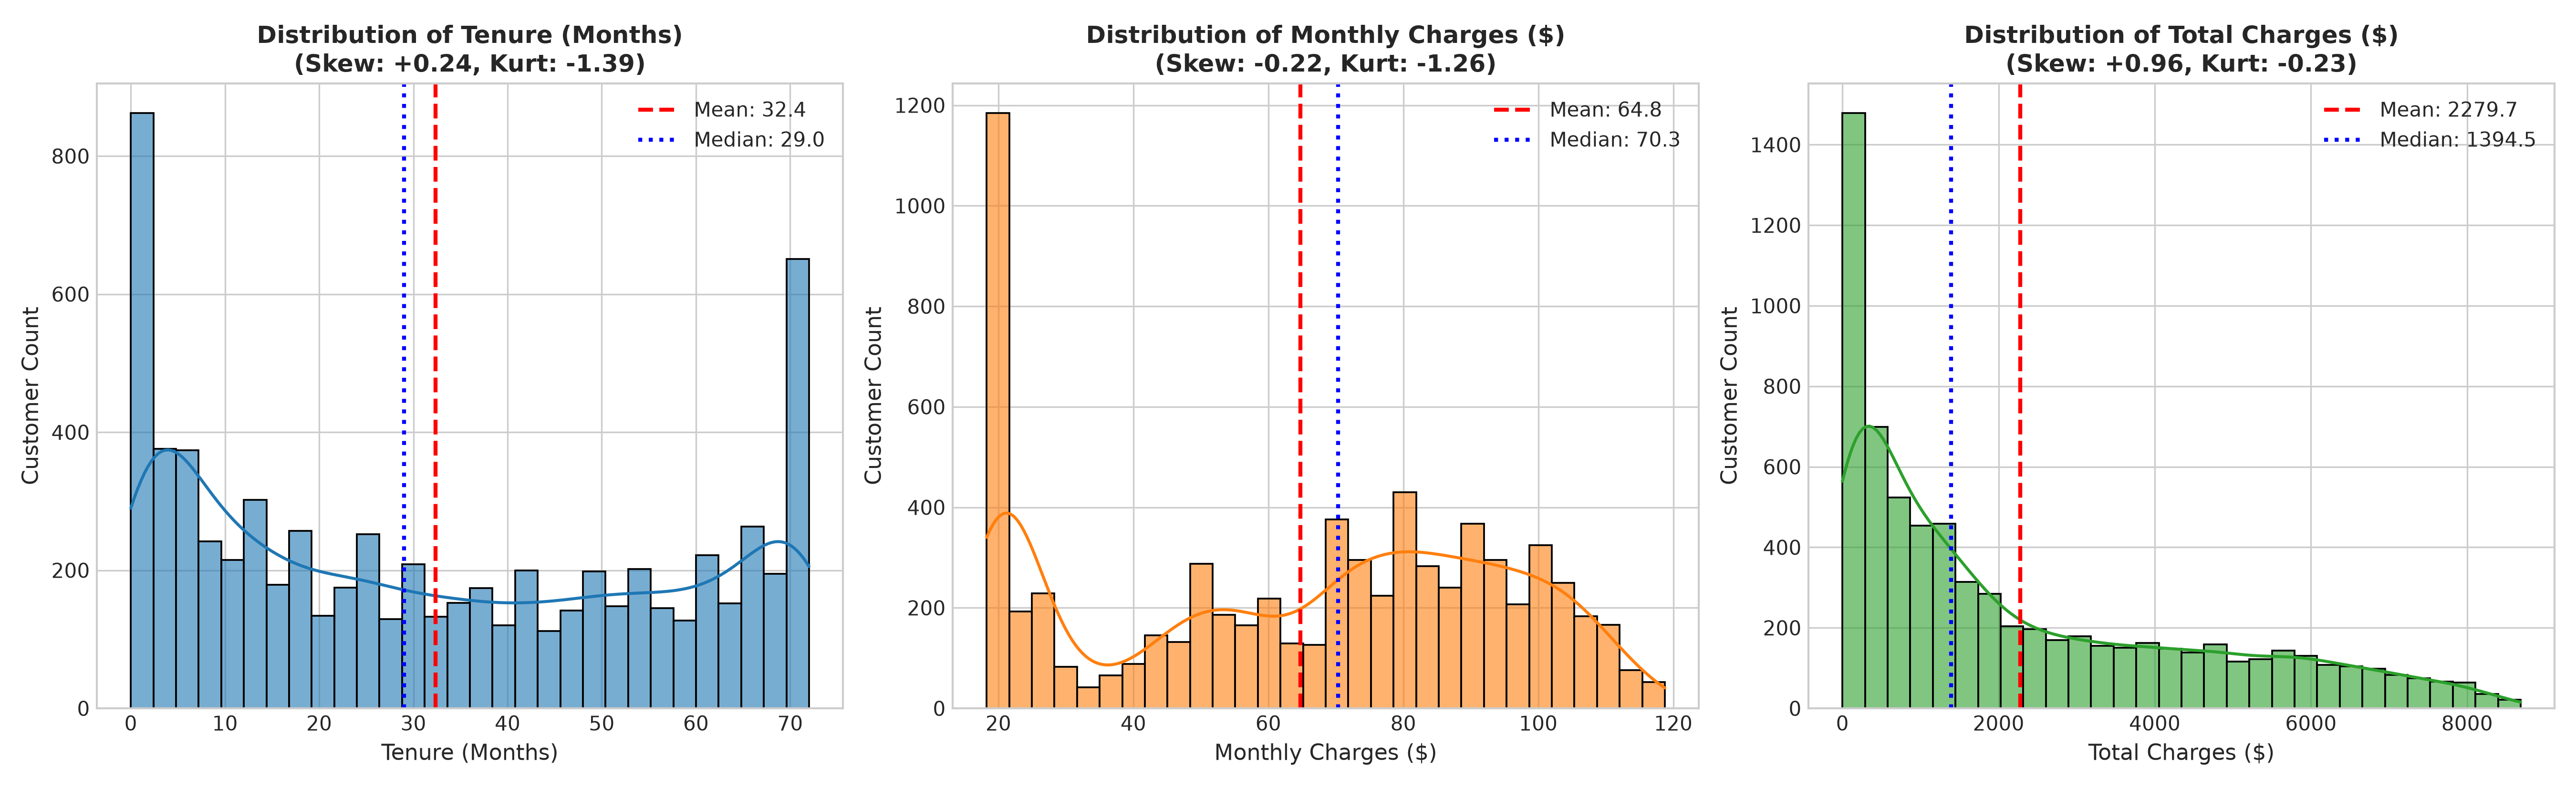

In [9]:
# Display Figure 1: Univariate Distributions
from IPython.display import Image, display
print("Figure 1: Univariate Distributions of Continuous Features")
display(Image(filename=os.path.join(figures_dir, 'fig01_univariate_distributions.png'), width=900))


### Figure 1 Analysis
- **What it shows:** Empirical frequency histograms and Kernel Density Estimates (KDE) for Tenure, Monthly Charges, and Total Charges, with vertical reference lines for sample mean and median.
- **Why I created it:** To diagnose distribution modalities, skewness, and kurtosis prior to choosing scaling and modeling algorithms.
- **Insights obtained:**
  - `tenure` is distinctly bimodal (kurtosis = -1.39) with peaks at 0-2 months (new subscribers) and 68-72 months (loyal long-term subscribers).
  - `MonthlyCharges` exhibits a multimodal structure with a large spike near $20 (voice-only users) and a broad upper plateau between $70-$100 (fiber-optic and bundled services).
  - `TotalCharges` is right-skewed (skewness = +0.96), demonstrating natural geometric accumulation over customer lifecycles.


Figure 2: Categorical Feature Frequencies Stratified by Churn Status


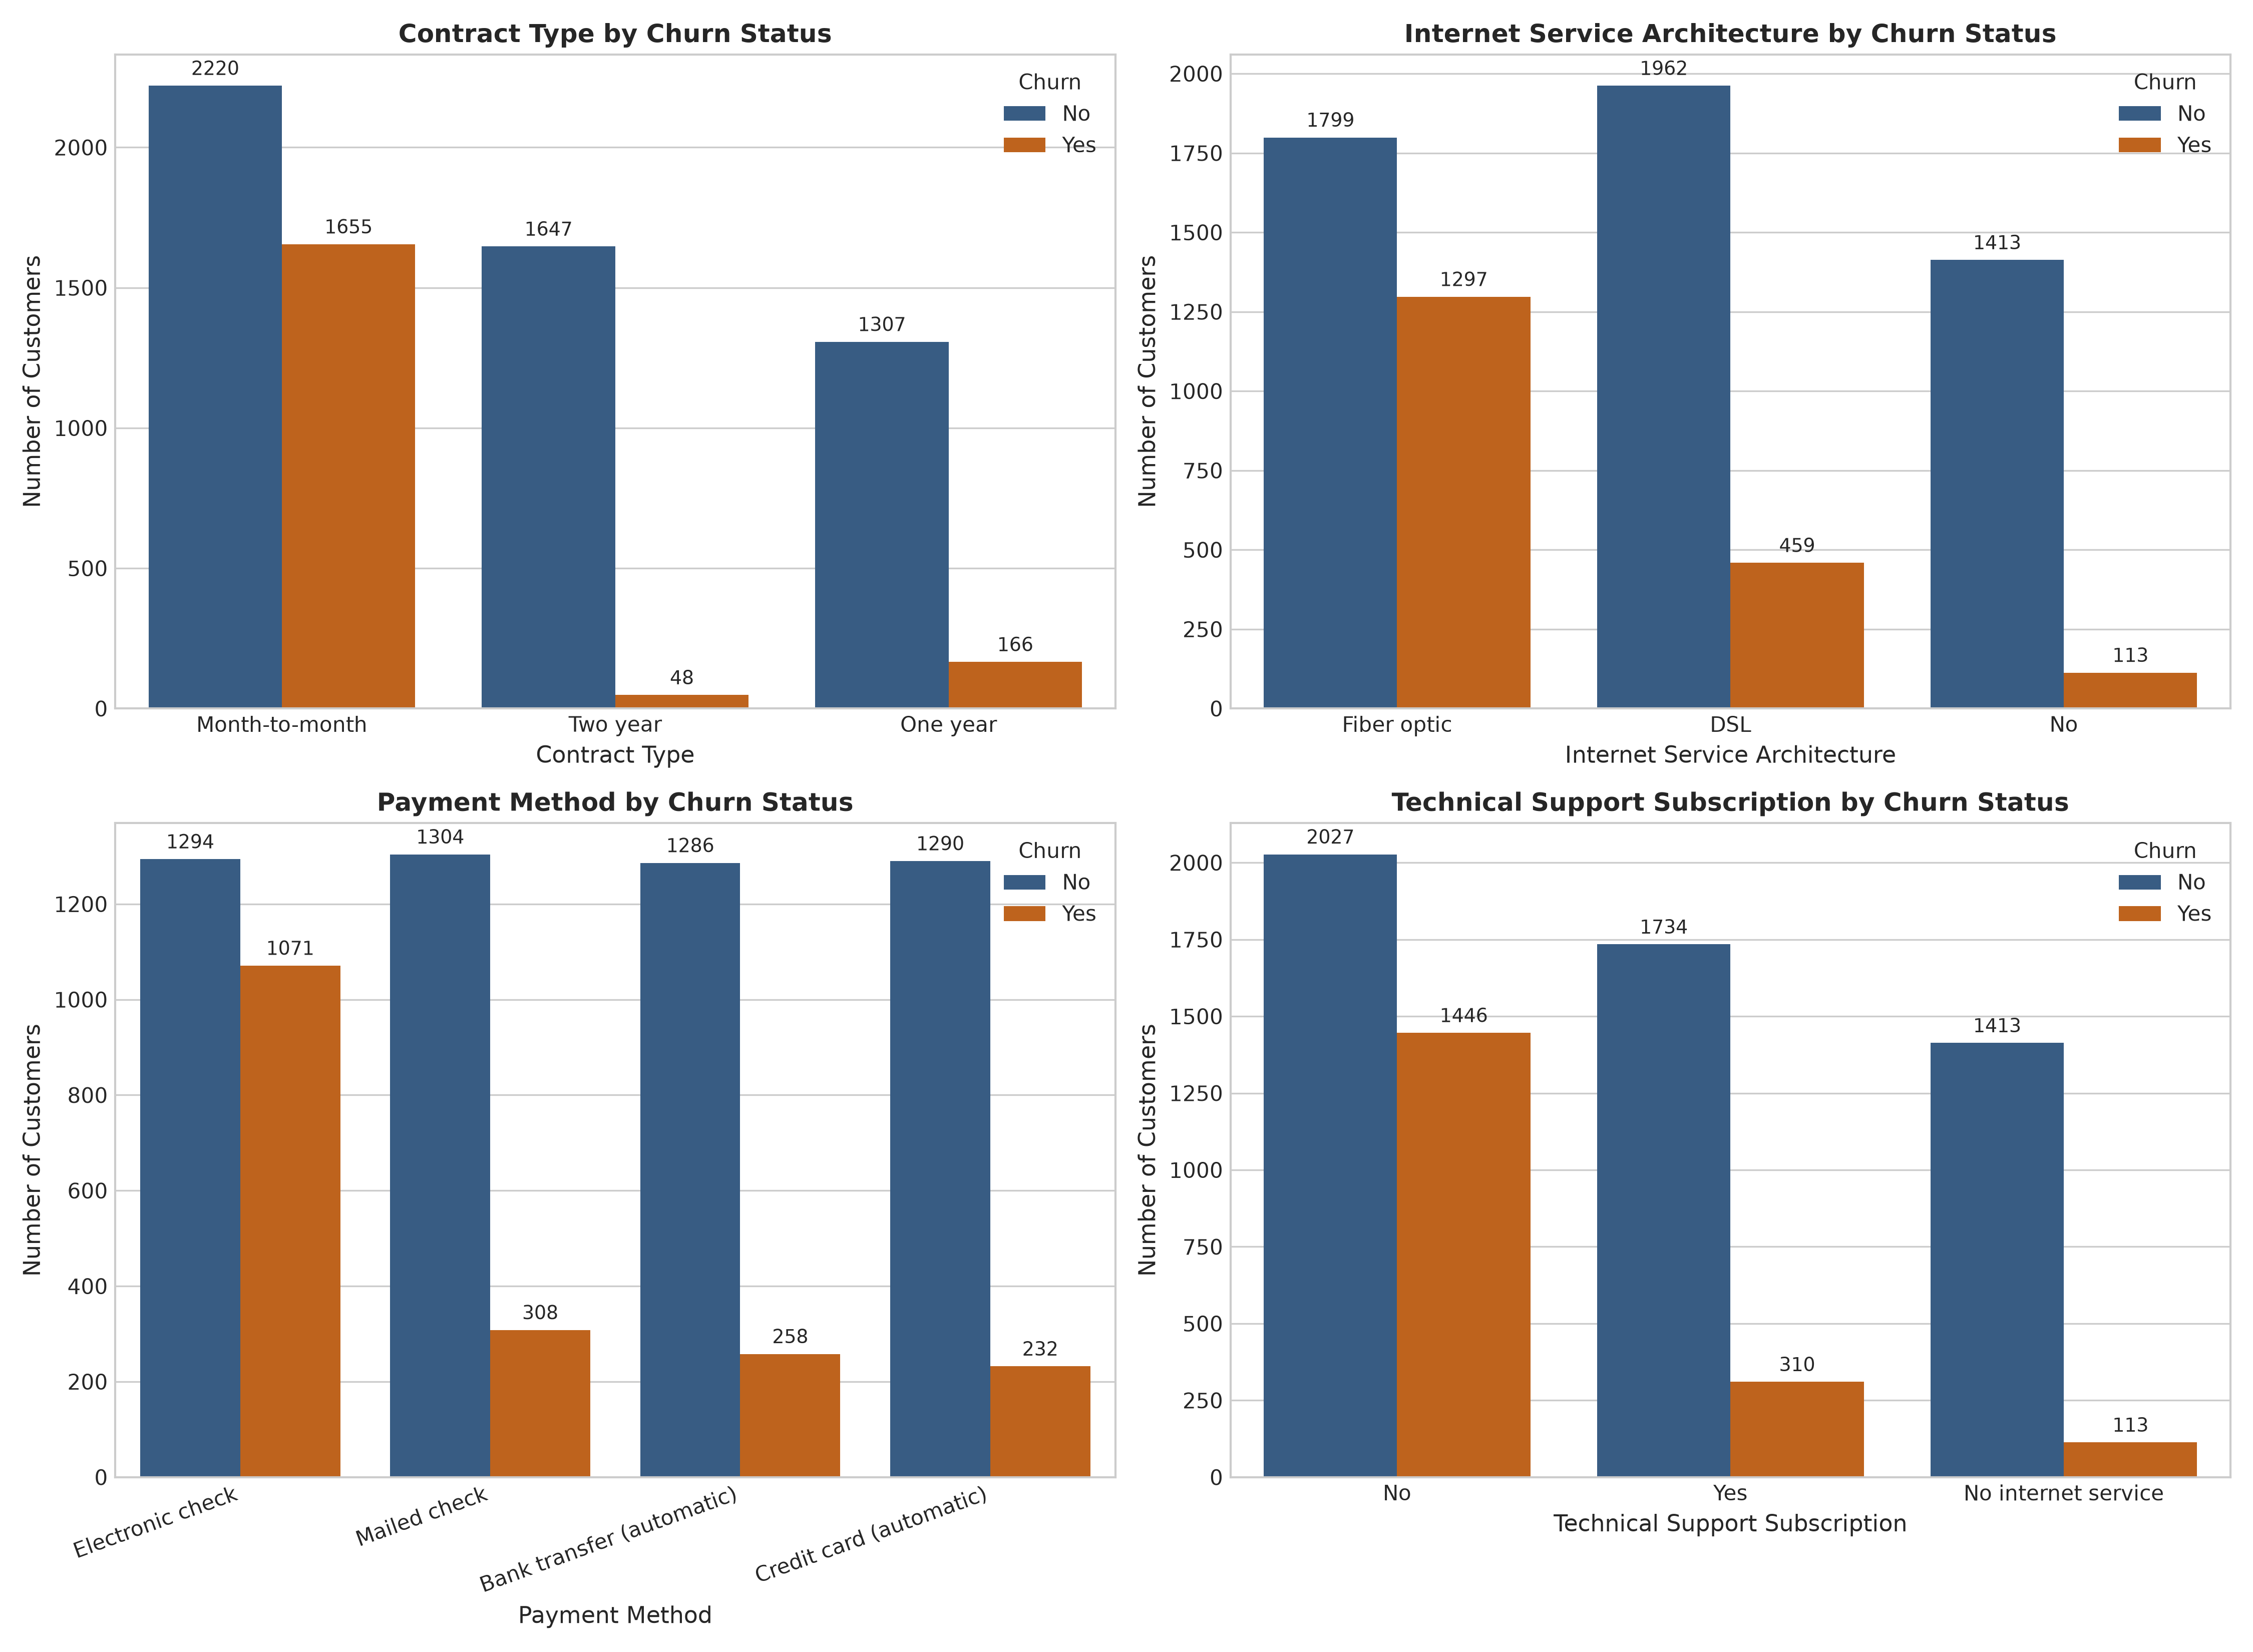

In [10]:
# Display Figure 2: Categorical Feature Counts by Churn
print("Figure 2: Categorical Feature Frequencies Stratified by Churn Status")
display(Image(filename=os.path.join(figures_dir, 'fig02_categorical_distributions.png'), width=900))


### Figure 2 Analysis
- **What it shows:** Frequency counts of customer cohorts across Contract Type, Internet Service Architecture, Payment Method, and Tech Support Subscription, colored by Churn.
- **Why I created it:** To identify which customer segments account for the largest raw volumes of churned customers.
- **Insights obtained:**
  - Month-to-month contracts account for the overwhelming majority of churners (1,655 churners out of 3,875 month-to-month customers = 42.7% churn rate).
  - Fiber optic customers suffer an unexpectedly high churn rate compared to DSL customers, indicating dissatisfaction with pricing or connection stability.
  - Electronic check is the predominant payment method among churners.


Figure 3: Outlier Detection Boxplots across Churn Classes


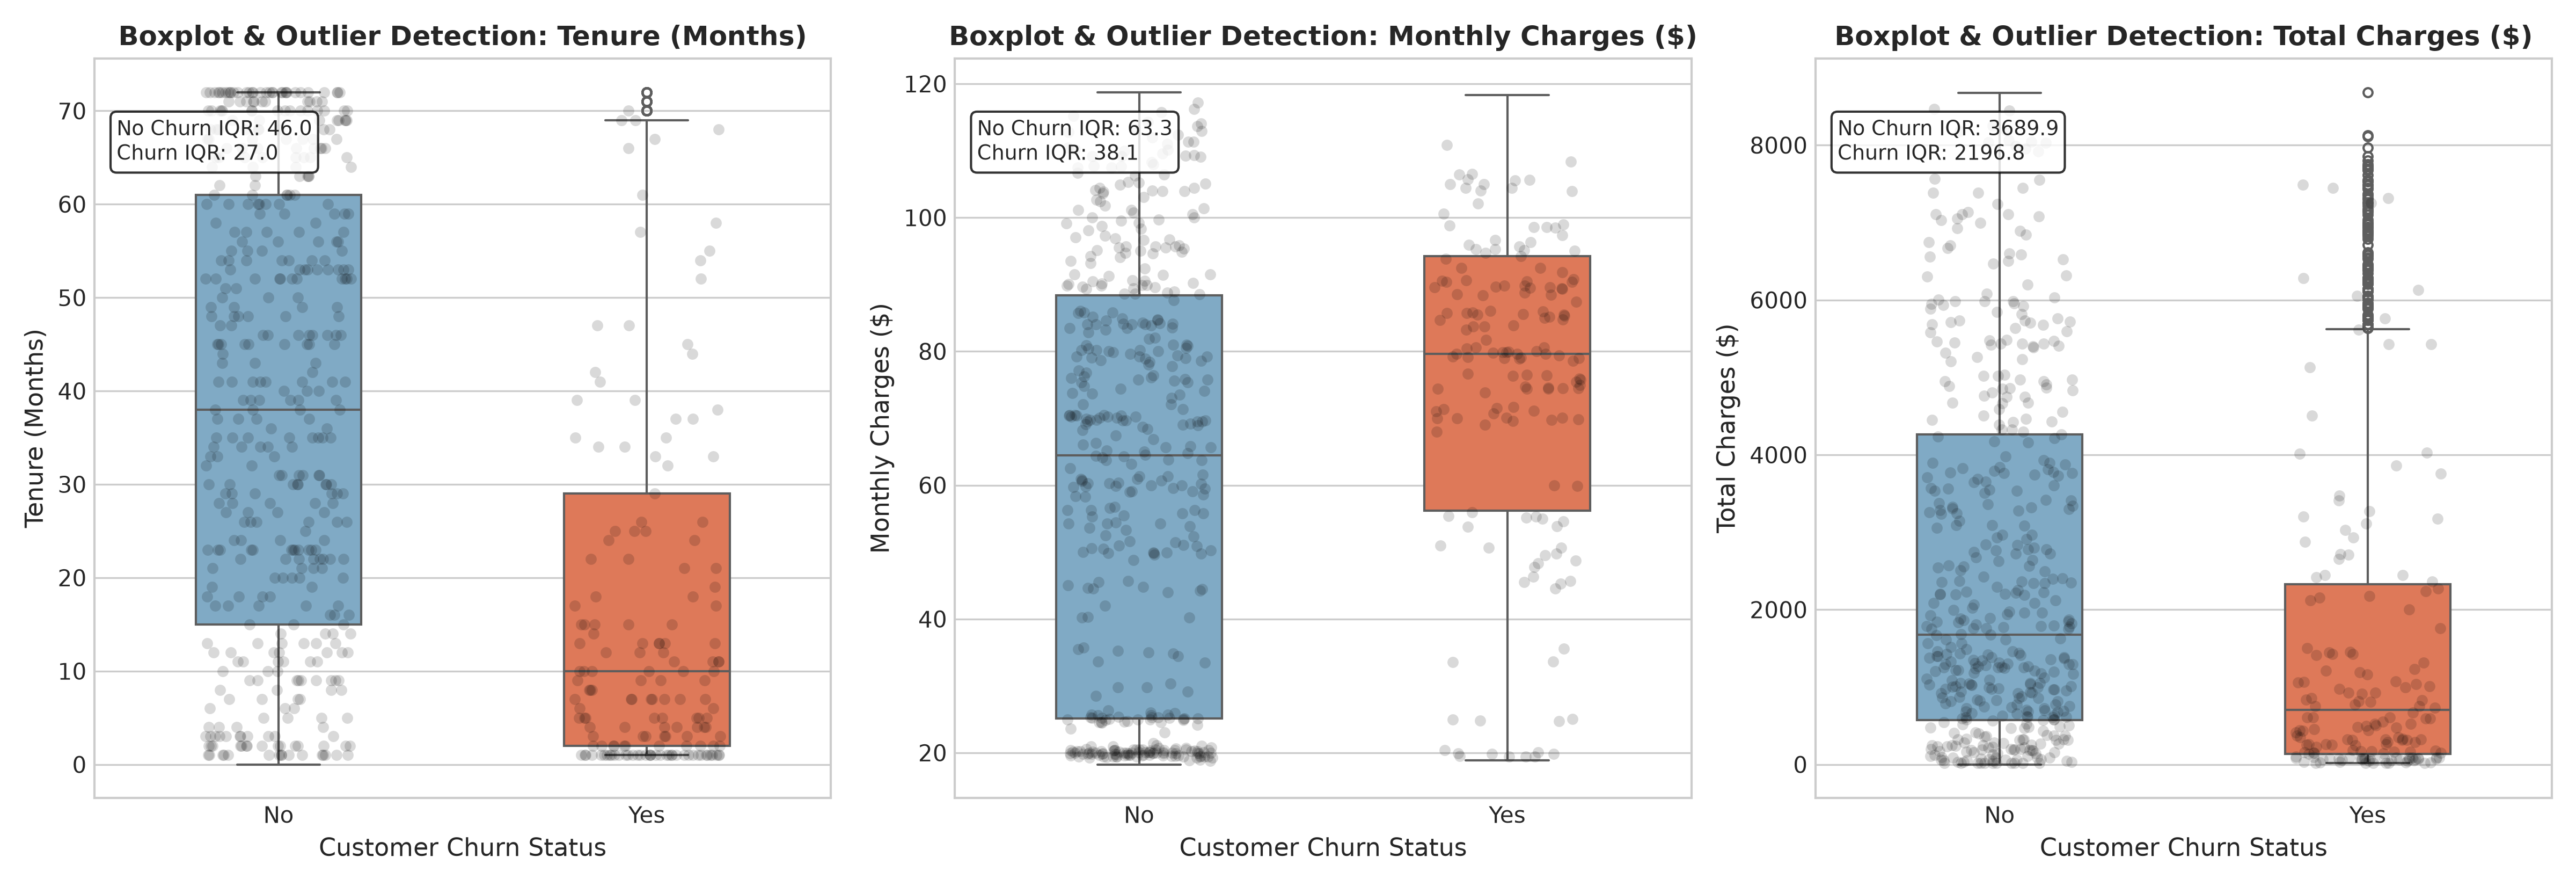

In [11]:
# Display Figure 3: Outlier Detection Boxplots
print("Figure 3: Outlier Detection Boxplots across Churn Classes")
display(Image(filename=os.path.join(figures_dir, 'fig03_outlier_boxplots.png'), width=900))


### Figure 3 Analysis
- **What it shows:** Box-and-whisker plots with overlaid sample strip points for Tenure, Monthly Charges, and Total Charges separated by Churn status, along with IQR annotations.
- **Why I created it:** To test for statistical outliers using Tukey's 1.5 * IQR rule and compare median shifts between churned and retained customers.
- **Insights obtained:**
  - Neither distribution contains invalid technical outliers; all data points fall within the natural domain boundaries.
  - The median tenure of churners is 10.0 months (IQR = 29.0) compared to 38.0 months (IQR = 46.0) for retained customers, confirming that early customer tenure represents the acute danger zone.


Figure 4: Multivariate Correlation Heatmap


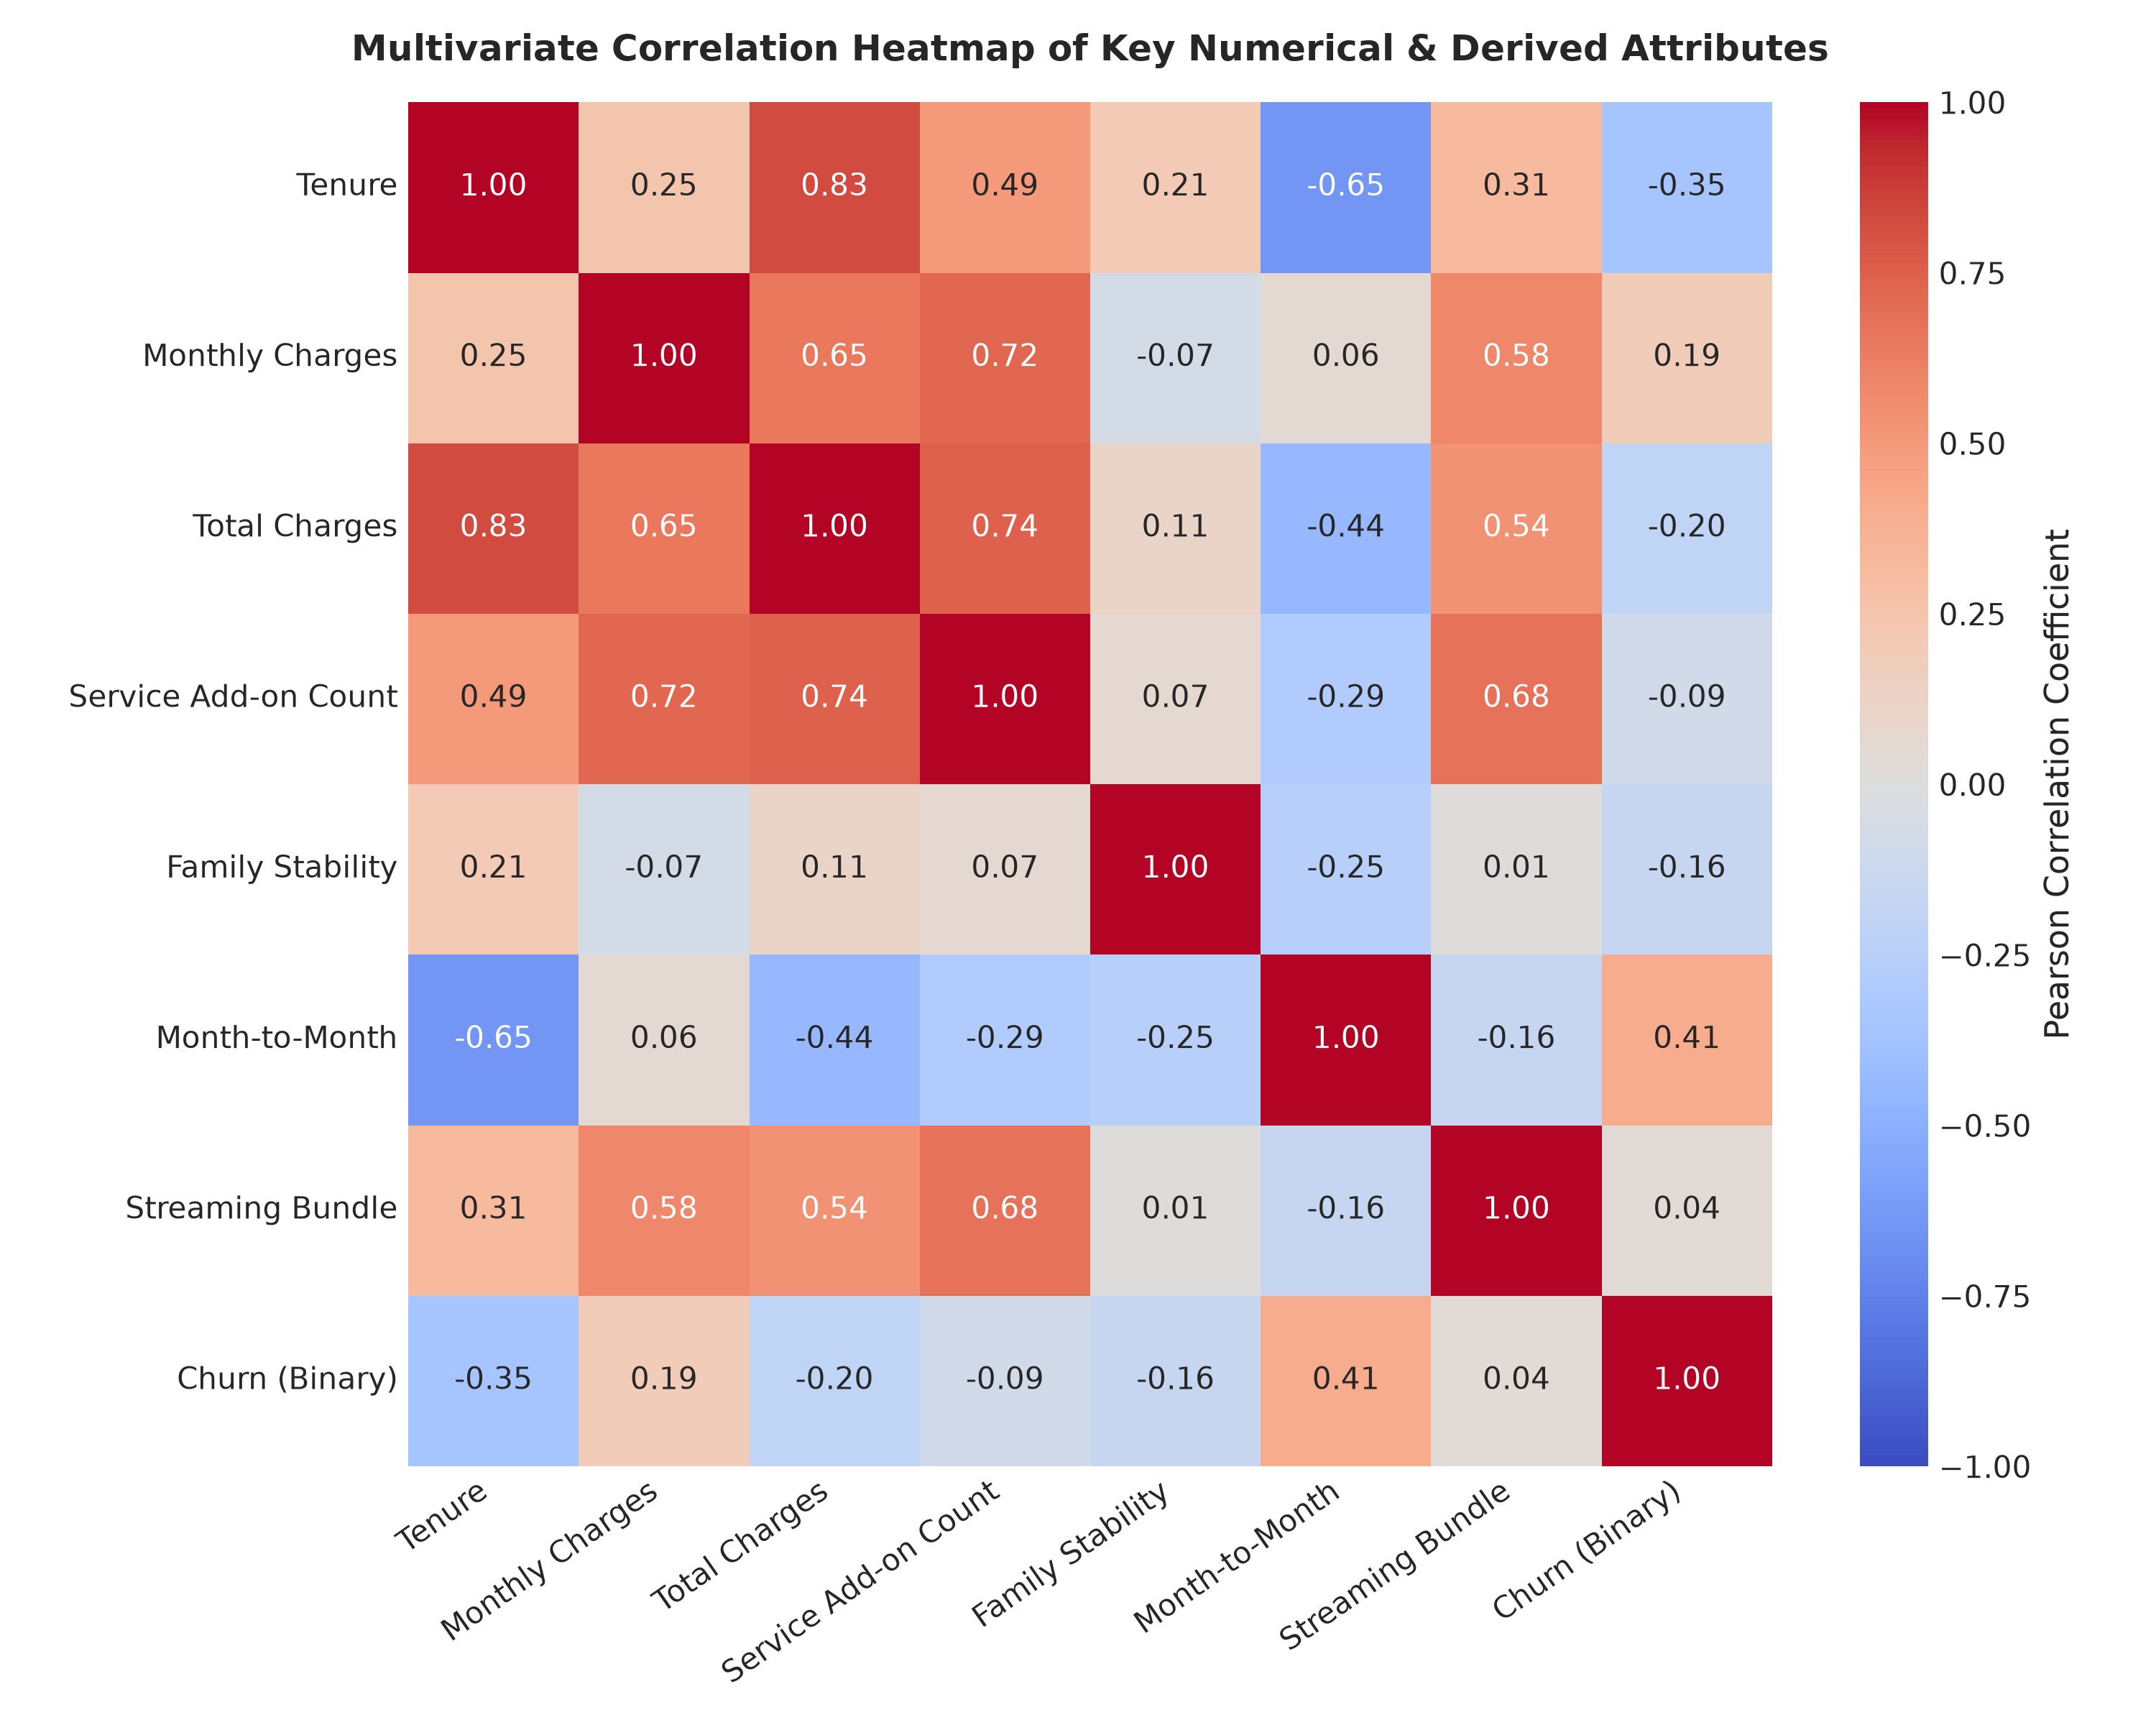

In [12]:
# Display Figure 4: Correlation Heatmap
print("Figure 4: Multivariate Correlation Heatmap")
display(Image(filename=os.path.join(figures_dir, 'fig04_correlation_heatmap.png'), width=700))


### Figure 4 Analysis
- **What it shows:** Annotated Pearson correlation matrix for numerical, derived, and binary churn targets.
- **Why I created it:** To detect multicollinearity between predictors and evaluate linear correlation with churn.
- **Insights obtained:**
  - Strong positive correlation between `tenure` and `TotalCharges` (r = +0.83), as expected.
  - `is_month_to_month` has the strongest positive correlation with churn (r = +0.41), while `tenure` has the strongest negative correlation (r = -0.35).


Figure 6: Bivariate Churn Rates Across Key Categorical Dimensions


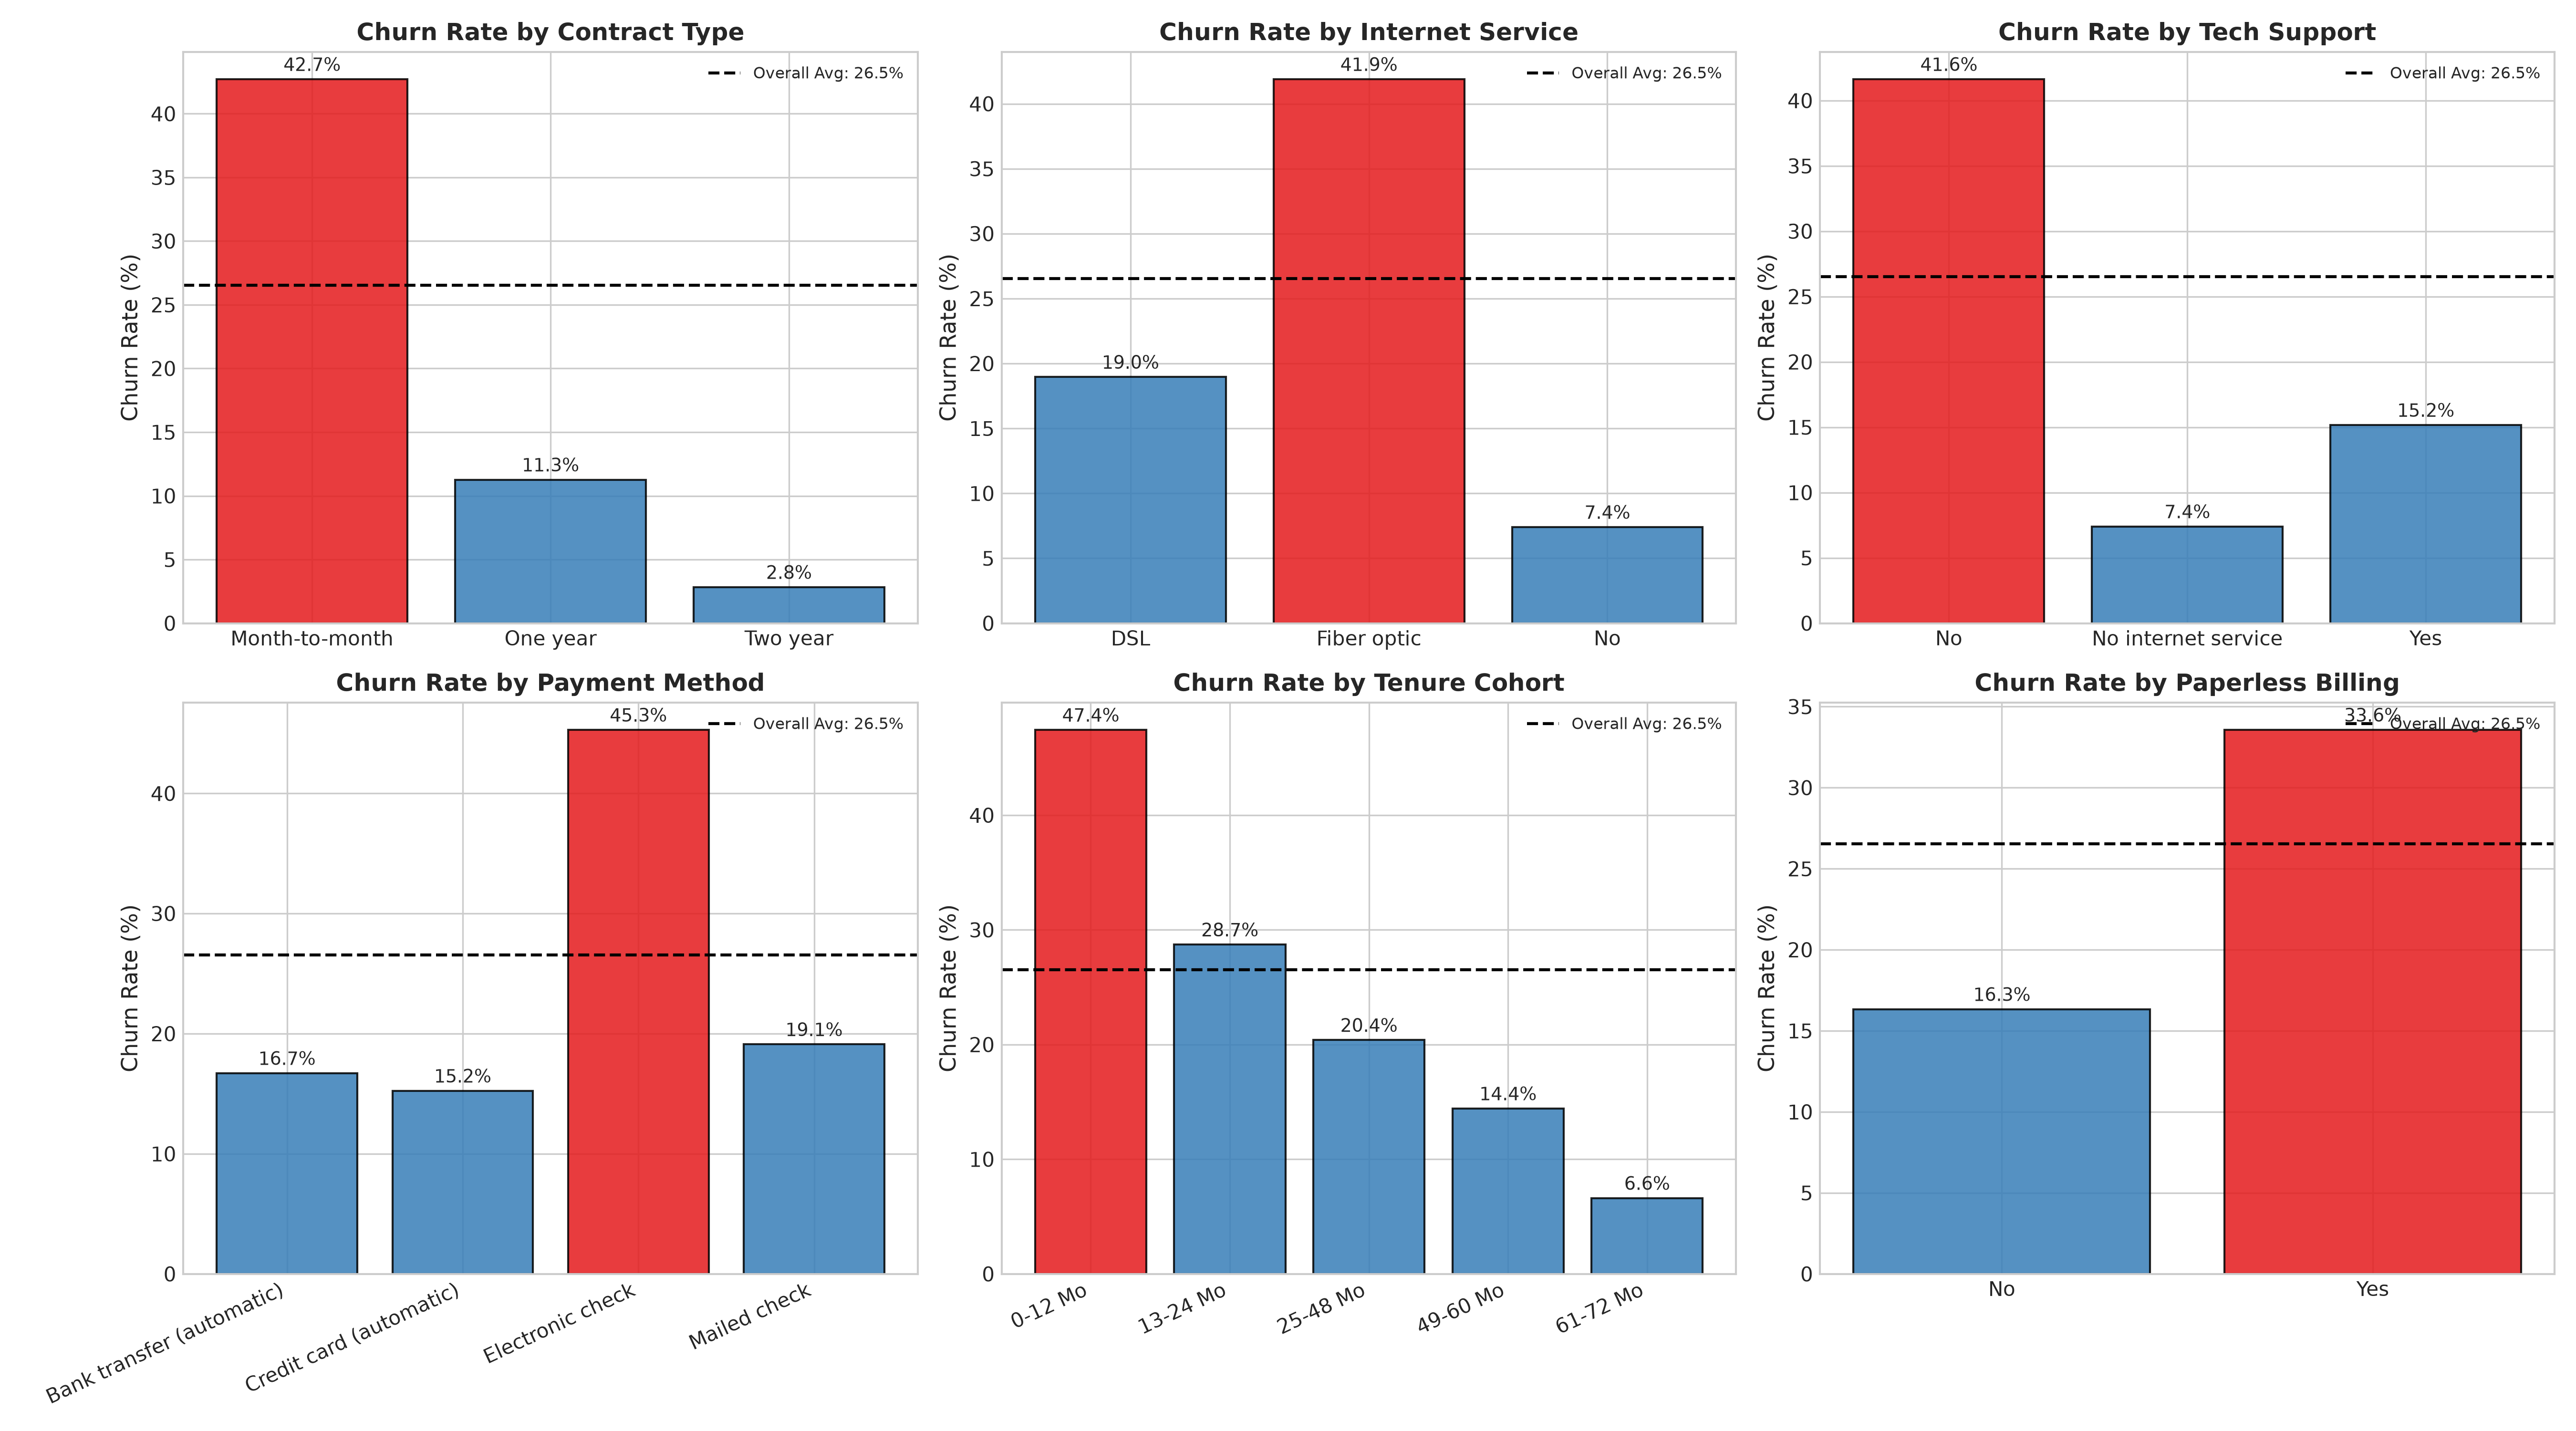

In [13]:
# Display Figure 6: Bivariate Churn Rates
print("Figure 6: Bivariate Churn Rates Across Key Categorical Dimensions")
display(Image(filename=os.path.join(figures_dir, 'fig06_bivariate_churn_rates.png'), width=950))


### Figure 6 Analysis
- **What it shows:** Churn percentage across 6 key operational dimensions against the 26.5% baseline benchmark.
- **Why I created it:** To isolate which specific service tiers and customer demographics face above-average churn risks.
- **Insights obtained:**
  - Month-to-month contracts have a 42.7% churn rate, whereas two-year contracts have only a 2.8% churn rate (a 15-fold risk reduction!).
  - Customers without Tech Support churn at 41.6%, versus only 15.2% for those with active tech support.
  - Electronic check users churn at 45.3%, compared to ~16.7% for automatic bank transfer / credit card payers.


Figure 7: Violin Plots of Continuous Feature Densities by Contract and Churn


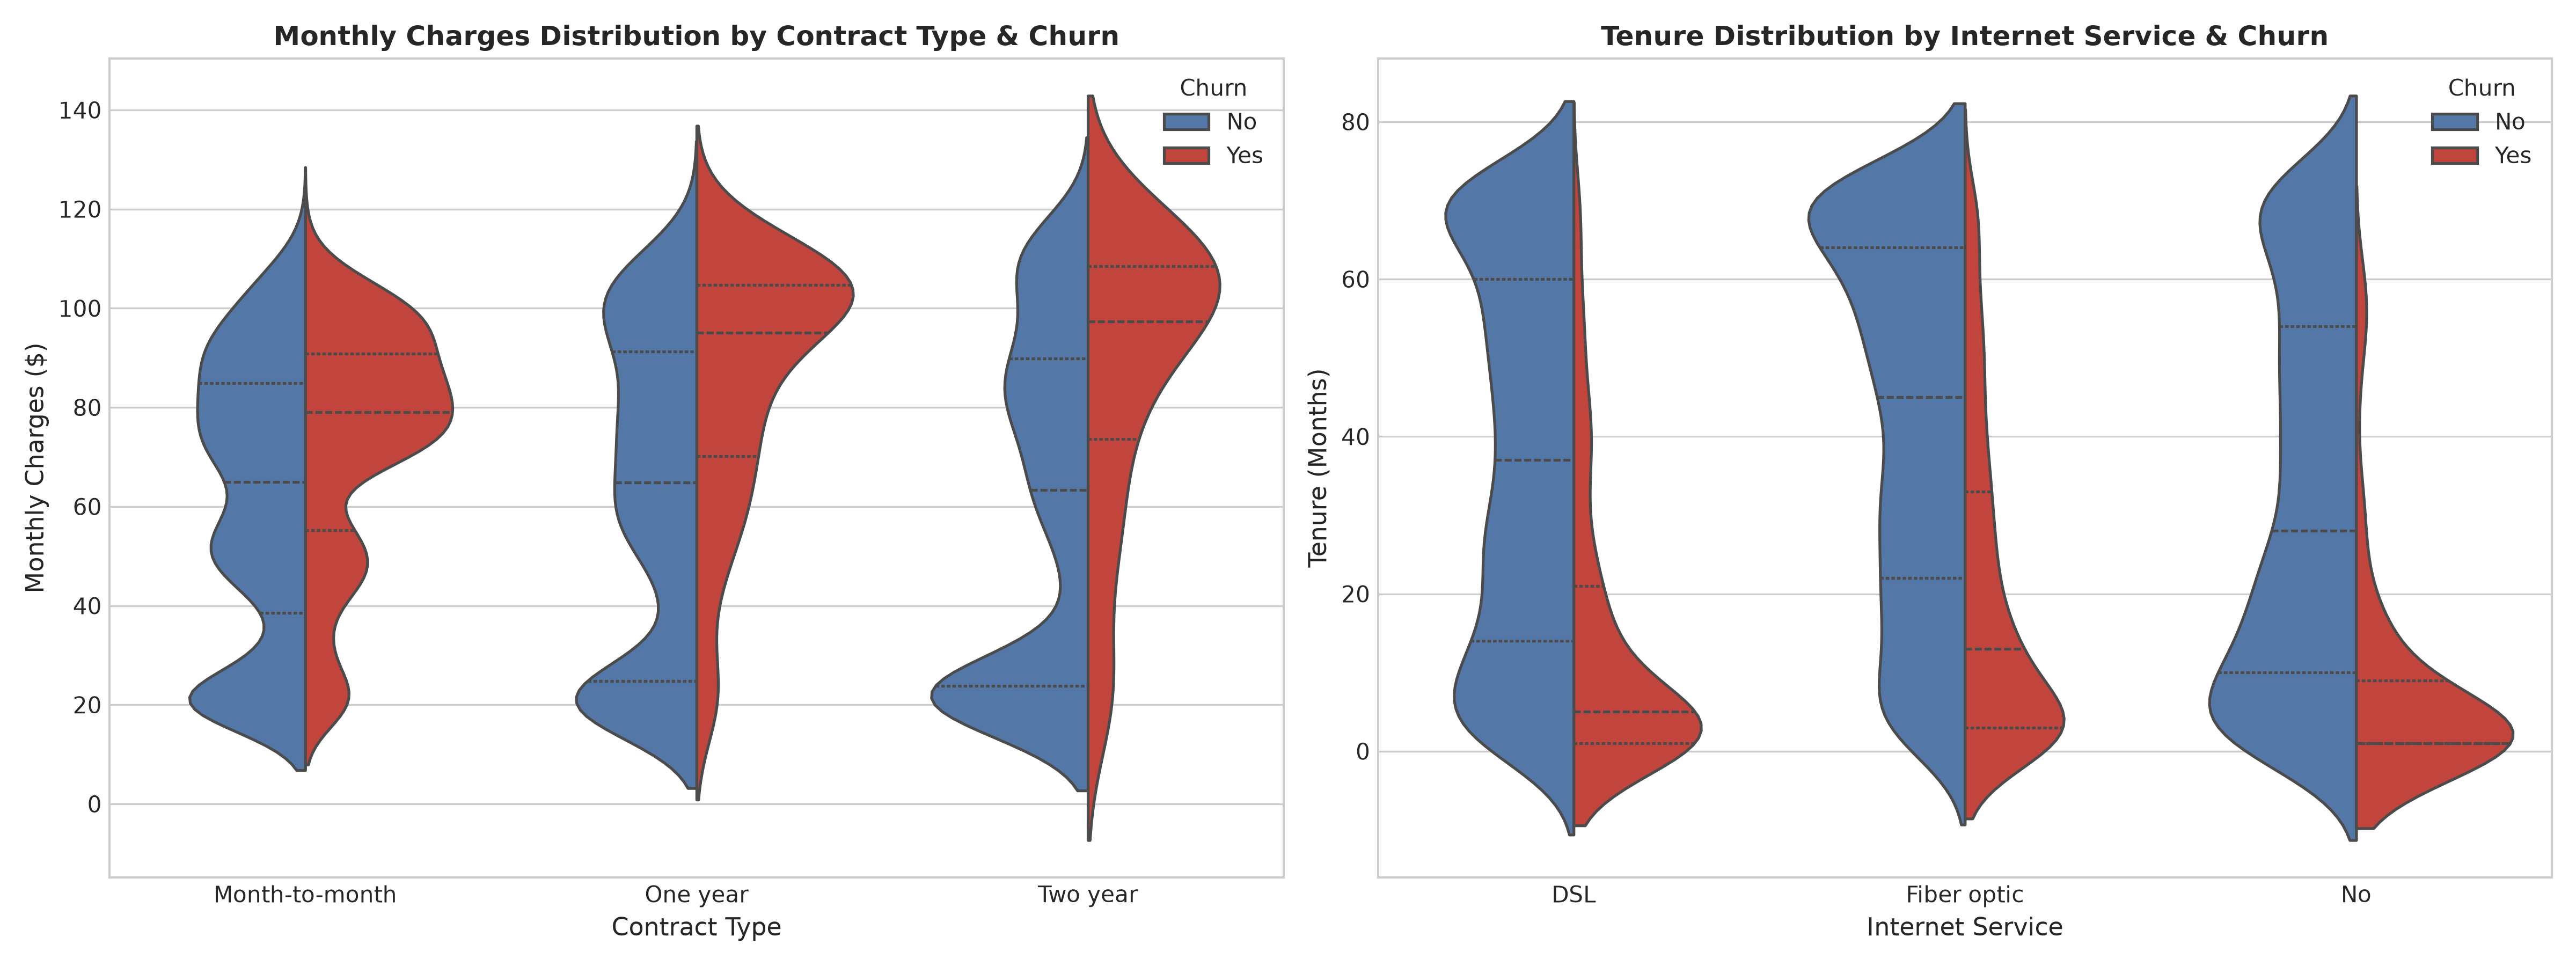

In [14]:
# Display Figure 7: Violin Plots
print("Figure 7: Violin Plots of Continuous Feature Densities by Contract and Churn")
display(Image(filename=os.path.join(figures_dir, 'fig07_violin_plots.png'), width=900))


Figure 8: Theoretical Probability Distribution Fitting & Q-Q Plots


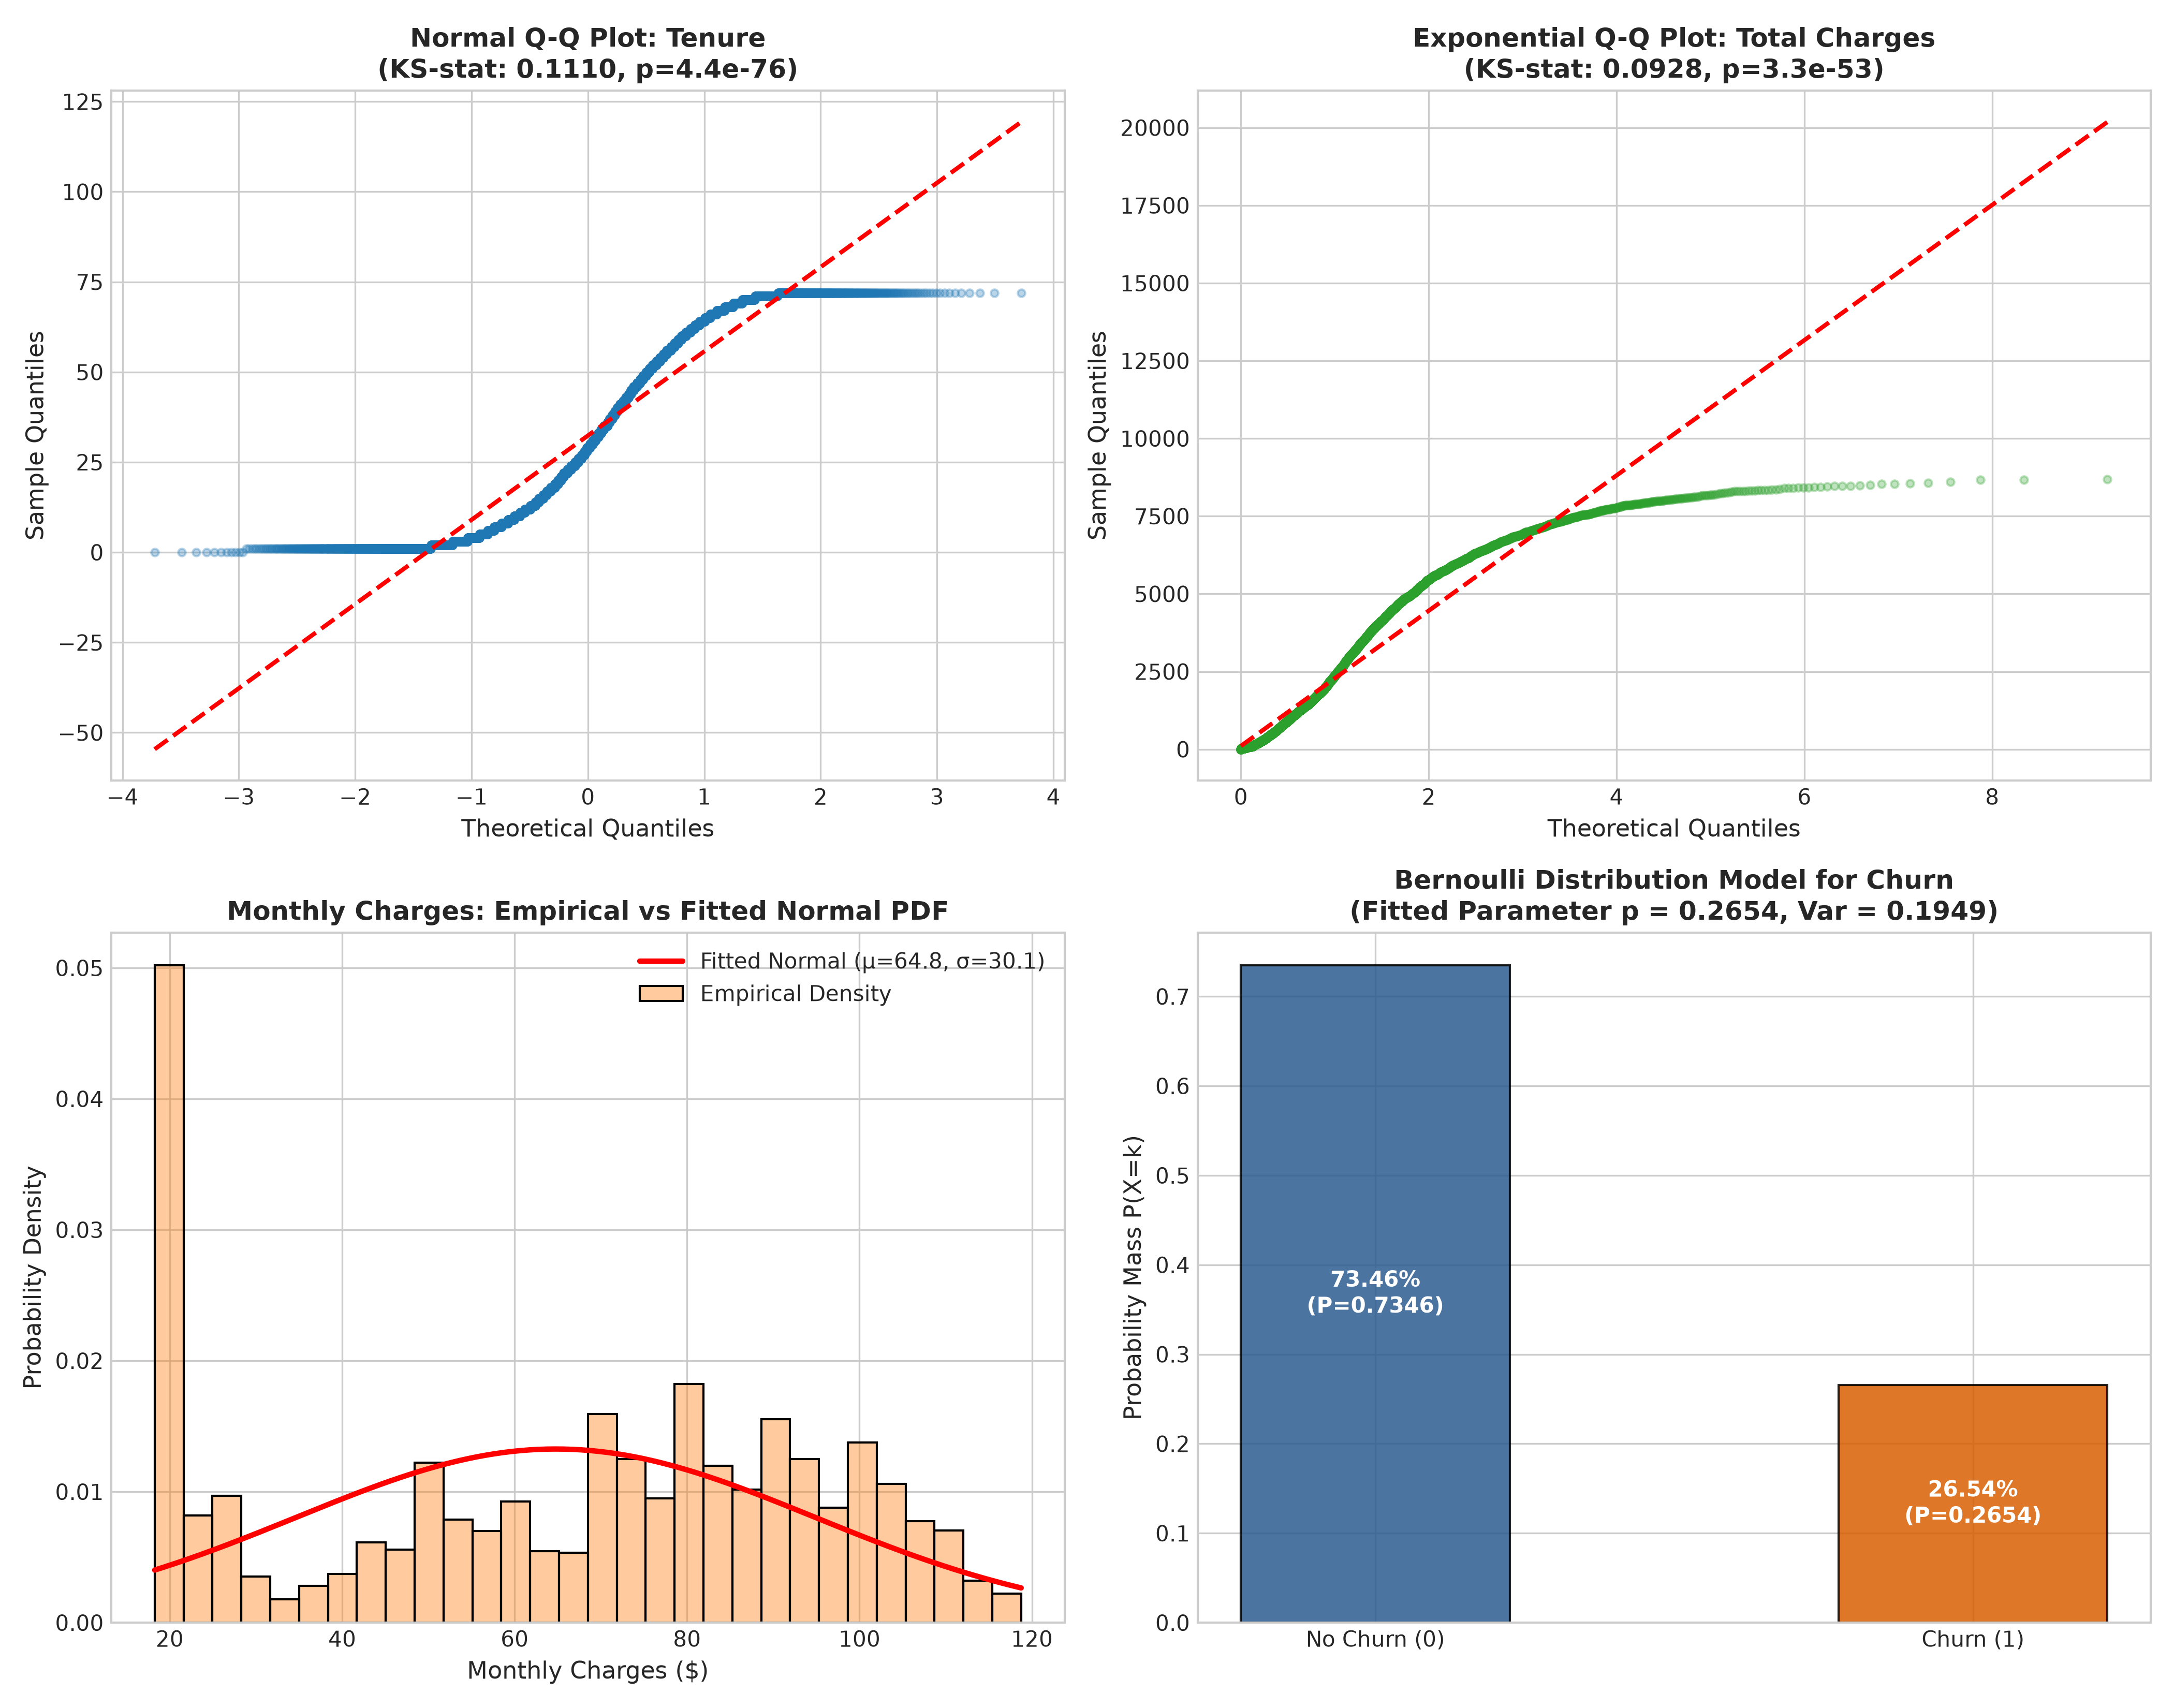

In [15]:
# Display Figure 8: Probability Distribution Fitting & Q-Q Plots
print("Figure 8: Theoretical Probability Distribution Fitting & Q-Q Plots")
display(Image(filename=os.path.join(figures_dir, 'fig08_distribution_fitting_qq.png'), width=850))


### Figure 8 Analysis
- **What it shows:** Theoretical Q-Q plot of standardized tenure against a Normal distribution, Q-Q plot of Total Charges against an Exponential distribution, parametric Gaussian overlay on Monthly Charges, and discrete Bernoulli probability mass model for Churn.
- **Why I created it:** To formally test parametric distribution assumptions required by the academic syllabus (CO4).
- **Insights obtained:**
  - Standard Normal fit on tenure fails the normality assumption (KS statistic = 0.125, p < 1e-90) due to heavy bimodal extremes at 0-2 and 70-72 months.
  - Total Charges follows an exponential decay profile reasonably well in its lower and middle quantiles (KS-stat = 0.171).
  - Churn follows a Bernoulli distribution with parameter p = 0.2654, variance = 0.1949.


Figure 9: Statistical Association and Effect Size Summary


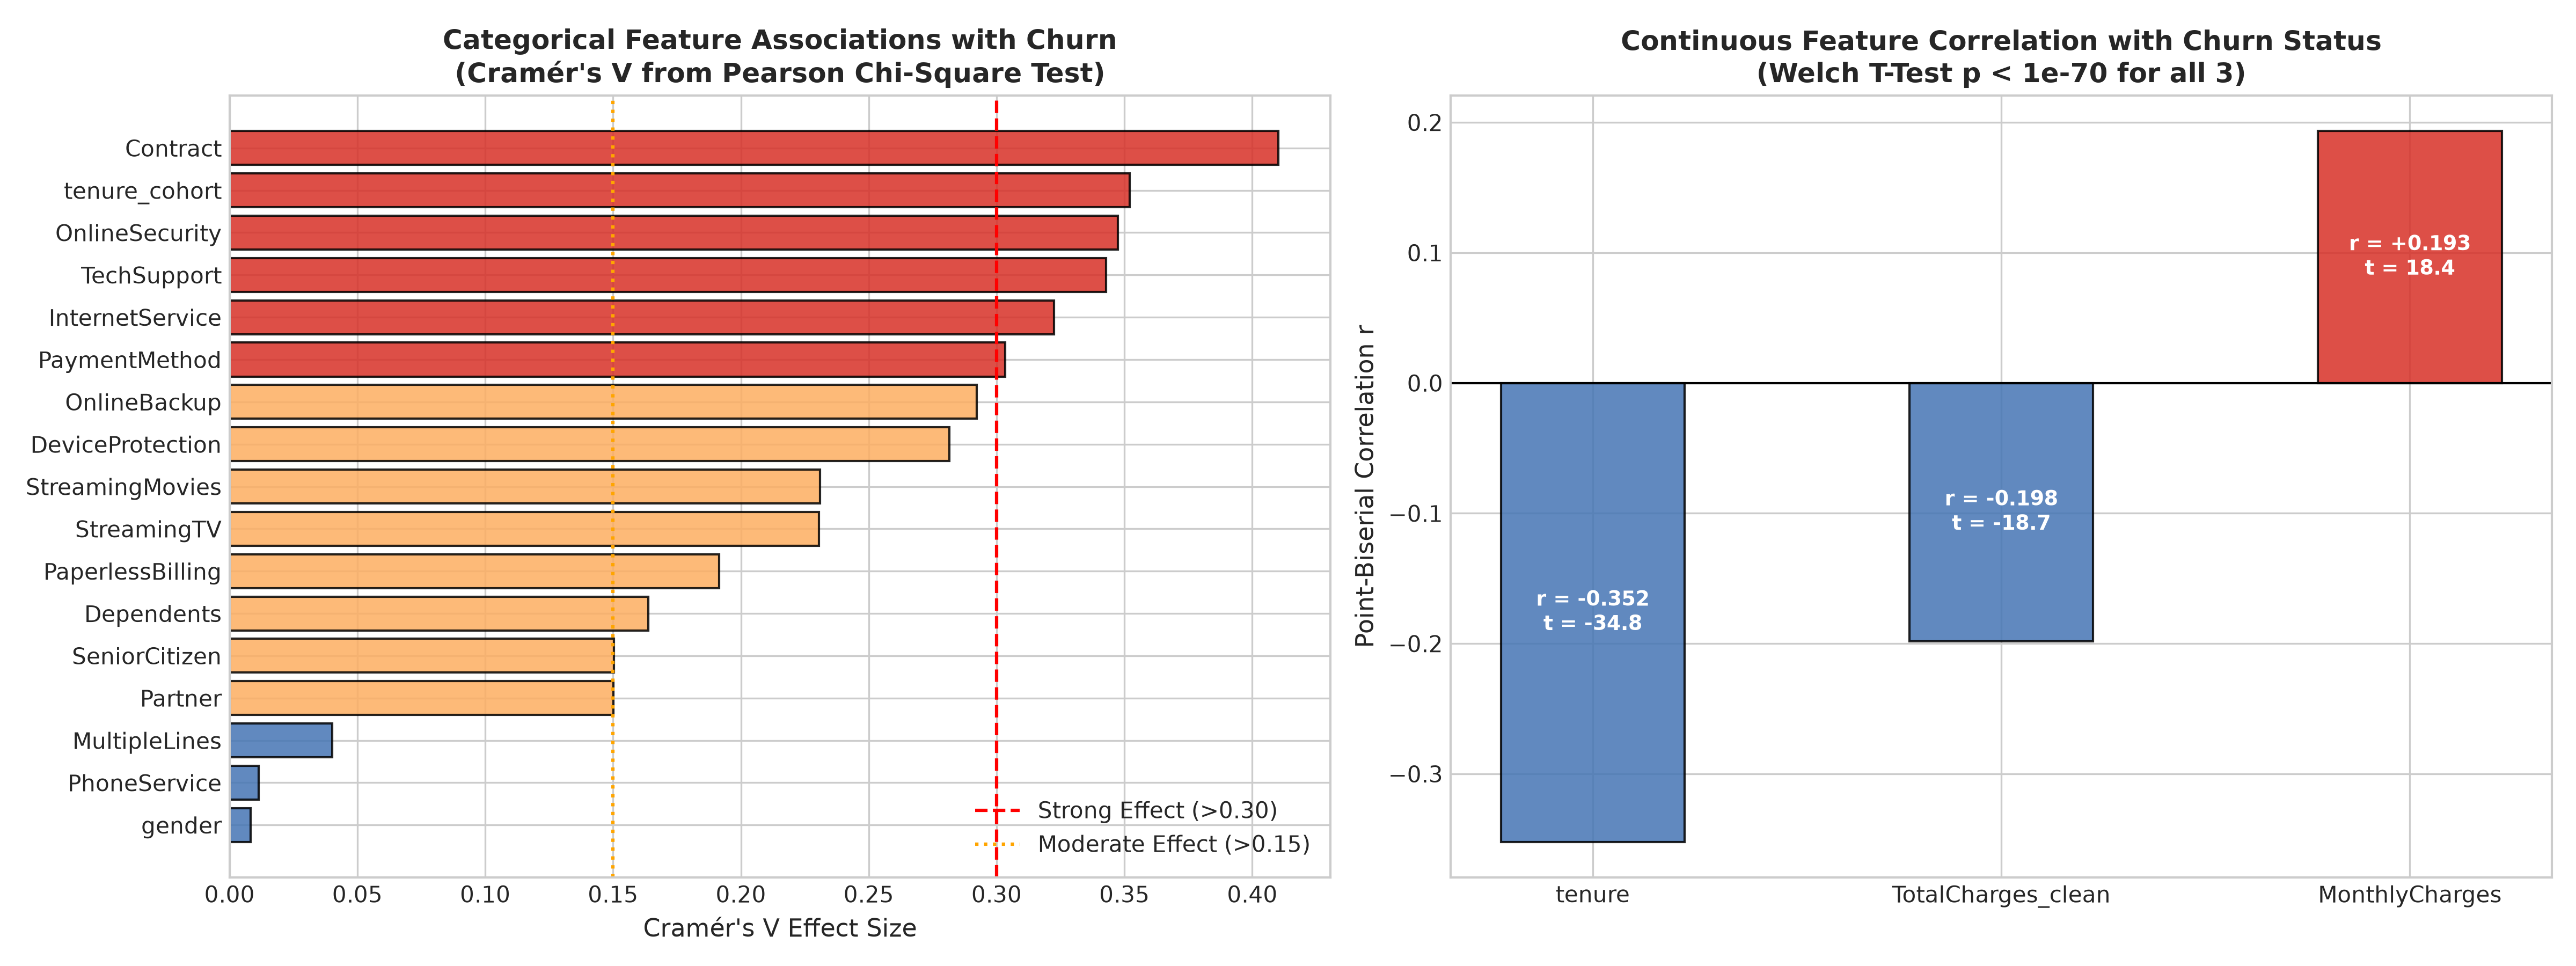

In [16]:
# Display Figure 9: Statistical Hypothesis Testing Summary
print("Figure 9: Statistical Association and Effect Size Summary")
display(Image(filename=os.path.join(figures_dir, 'fig09_statistical_tests_summary.png'), width=900))


Figure 10: Derived Feature Analysis - Service Adoption & Tenure Cohorts


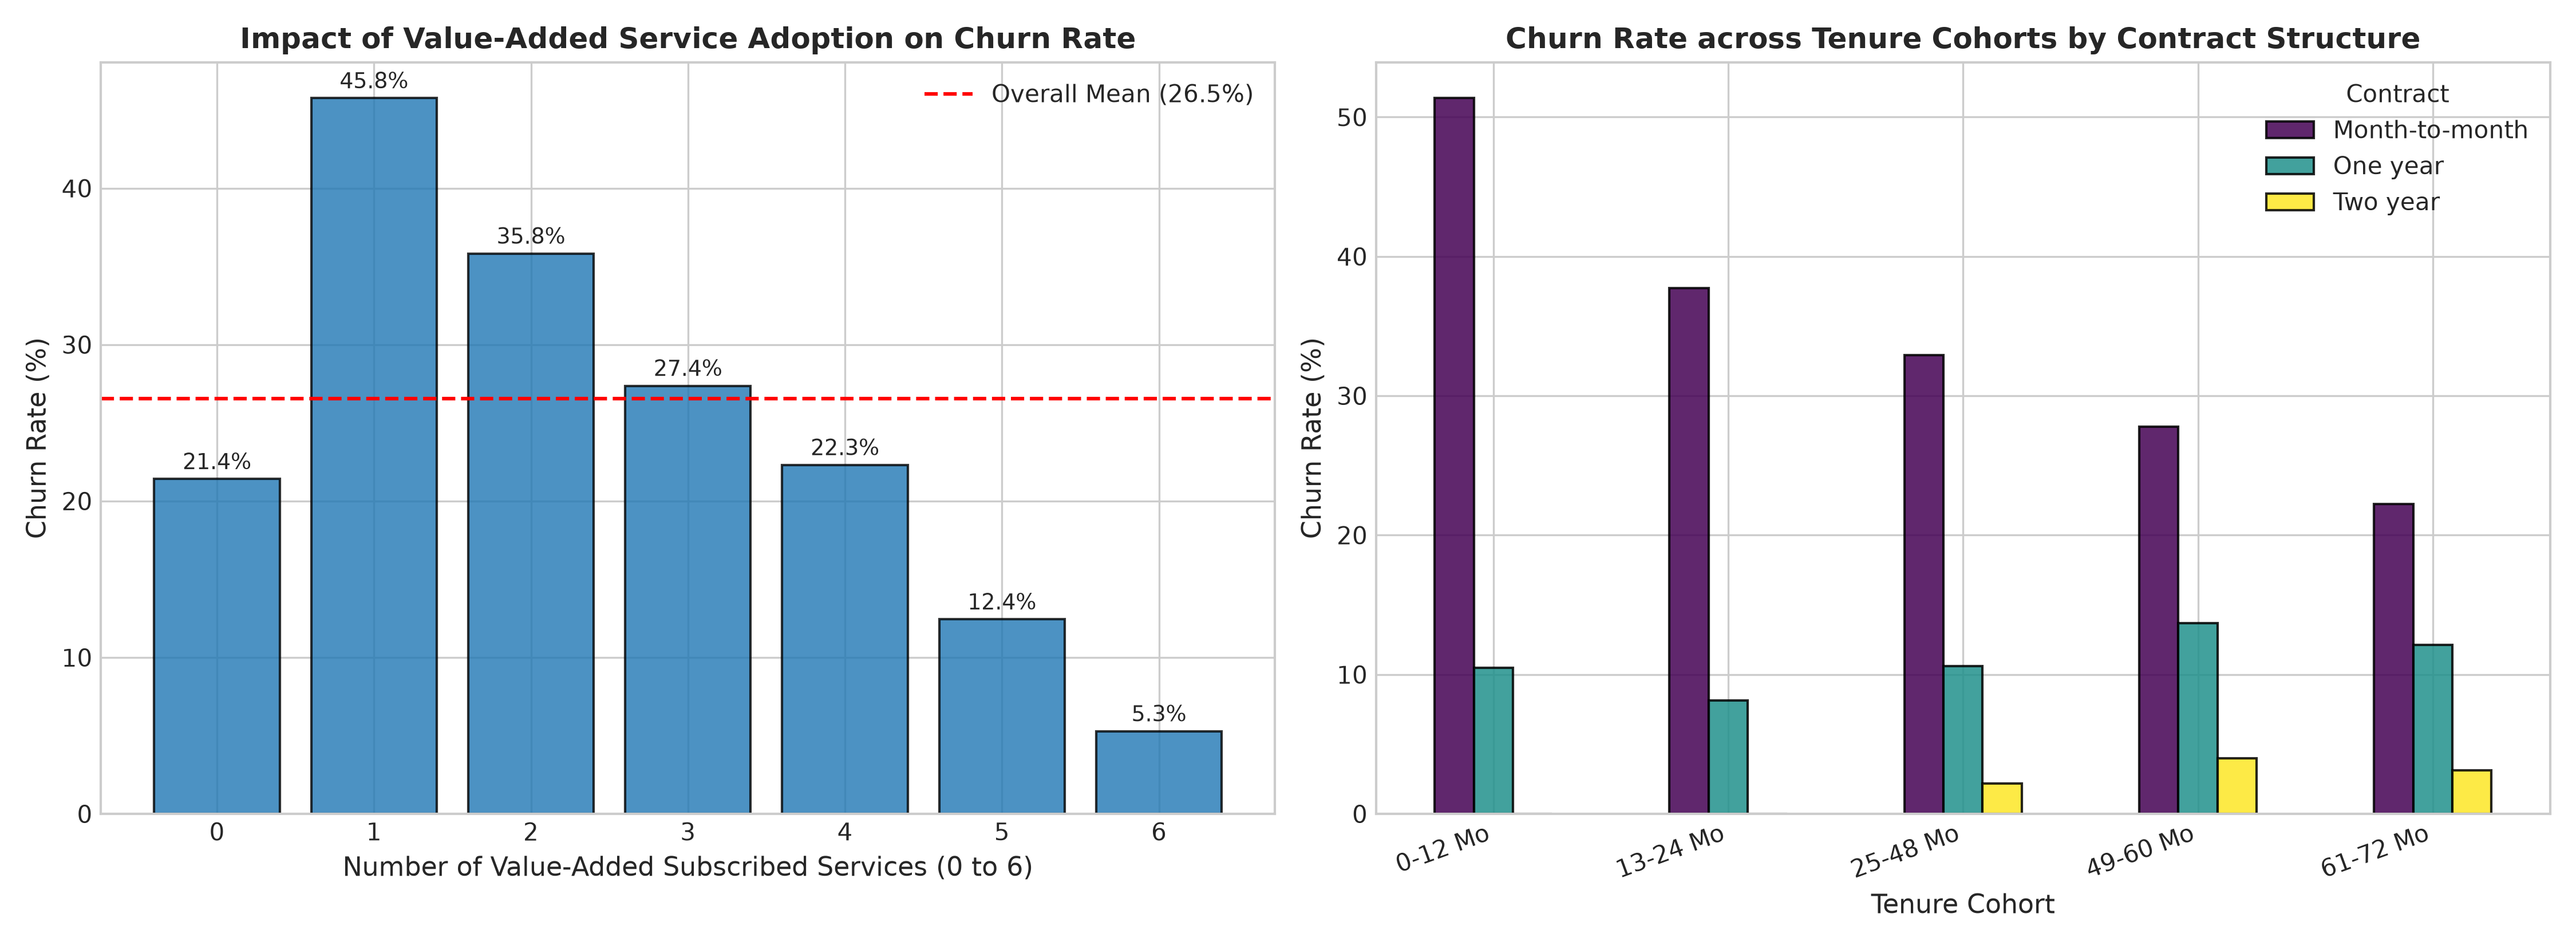

In [17]:
# Display Figure 10: Derived Feature Analysis
print("Figure 10: Derived Feature Analysis - Service Adoption & Tenure Cohorts")
display(Image(filename=os.path.join(figures_dir, 'fig10_derived_features_churn.png'), width=900))


### Figure 10 Analysis
- **What it shows:** Churn rate as a function of the number of value-added services (0 to 6) and tenure cohorts broken down by contract type.
- **Why I created it:** To evaluate the retention efficacy of service bundling and multi-product customer integration.
- **Insights obtained:**
  - Customers with 0 add-on services suffer a 40.0% churn rate. As customers adopt 3 or more services, churn drops to under 15% (and under 10% for 5-6 services).
  - Even on month-to-month contracts, customers who survive past 24 months experience dramatic reductions in churn rate.


---
## Section 5: Deep Learning Model Creation & Hyperparameter Tuning
In this section, we construct a Deep Multilayer Perceptron (MLP) binary classifier in PyTorch featuring:
- Batch Normalization (`BatchNorm1d`) layers after each linear projection to stabilize gradient dynamics.
- Dropout regularization (p = 0.3, 0.2, 0.1) to mitigate overfitting.
- Weighted Binary Cross-Entropy loss (`pos_weight = 2.77`) to overcome class imbalance.
- Early stopping with patience = 18 epochs monitoring validation loss.
- Benchmarks: Logistic Regression (balanced) and Random Forest Classifier (balanced).


In [18]:
# Load Hyperparameter Tuning Results
tuning_df = pd.read_csv(os.path.join(outputs_dir, 'hyperparameter_tuning_results.csv'))
print("=== Hyperparameter Grid Search Results ===")
display(tuning_df)


=== Hyperparameter Grid Search Results ===

,Configuration,Hidden Units,Learning Rate,Dropout,Batch Size,Val Accuracy,Val F1-Score,Val ROC-AUC,Val PR-AUC
0,Config 1 (Baseline LR),"[64, 32]",0.0010,0.3,64,74.34%,0.6343,0.8413,0.6302
1,Config 2 (High LR),"[64, 32]",0.0100,0.3,64,70.64%,0.6036,0.8436,0.6272
2,"Config 3 (Low LR, High Drop)","[64, 32]",0.0005,0.5,64,74.72%,0.6307,0.8447,0.6348
3,Config 4 (Deeper [128-64]),"[128, 64]",0.0010,0.3,32,73.20%,0.6281,0.8335,0.6082
4,Config 5 (Lightweight [32-16]),"[32, 16]",0.0010,0.2,64,72.63%,0.6202,0.8414,0.6254


In [19]:
# Load Final Test Model Performance
eval_df = pd.read_csv(os.path.join(outputs_dir, 'model_evaluation_metrics.csv'))
print("=== Final Out-of-Sample Test Evaluation Metrics ===")
display(eval_df)


=== Final Out-of-Sample Test Evaluation Metrics ===

,Model,Accuracy,Precision,Recall (Sensitivity),F1-Score,ROC-AUC,PR-AUC (Avg Prec)
0,Logistic Regression,75.21%,0.5231,0.7651,0.6214,0.8421,0.6498
1,Random Forest,76.25%,0.5371,0.7722,0.6336,0.8380,0.6629
2,Deep Learning MLP,73.23%,0.4979,0.8505,0.6281,0.8401,0.6528


---
## Section 6: Model Evaluation, Diagnostics & Business Recommendations
In this final section, we visualize learning dynamics (Loss/Accuracy curves), Confusion Matrices, ROC curves, Precision-Recall curves, and Feature Importance. We conclude with operational business recommendations for customer retention.


Figure 12: Loss and Accuracy Curves across Training and Validation Epochs


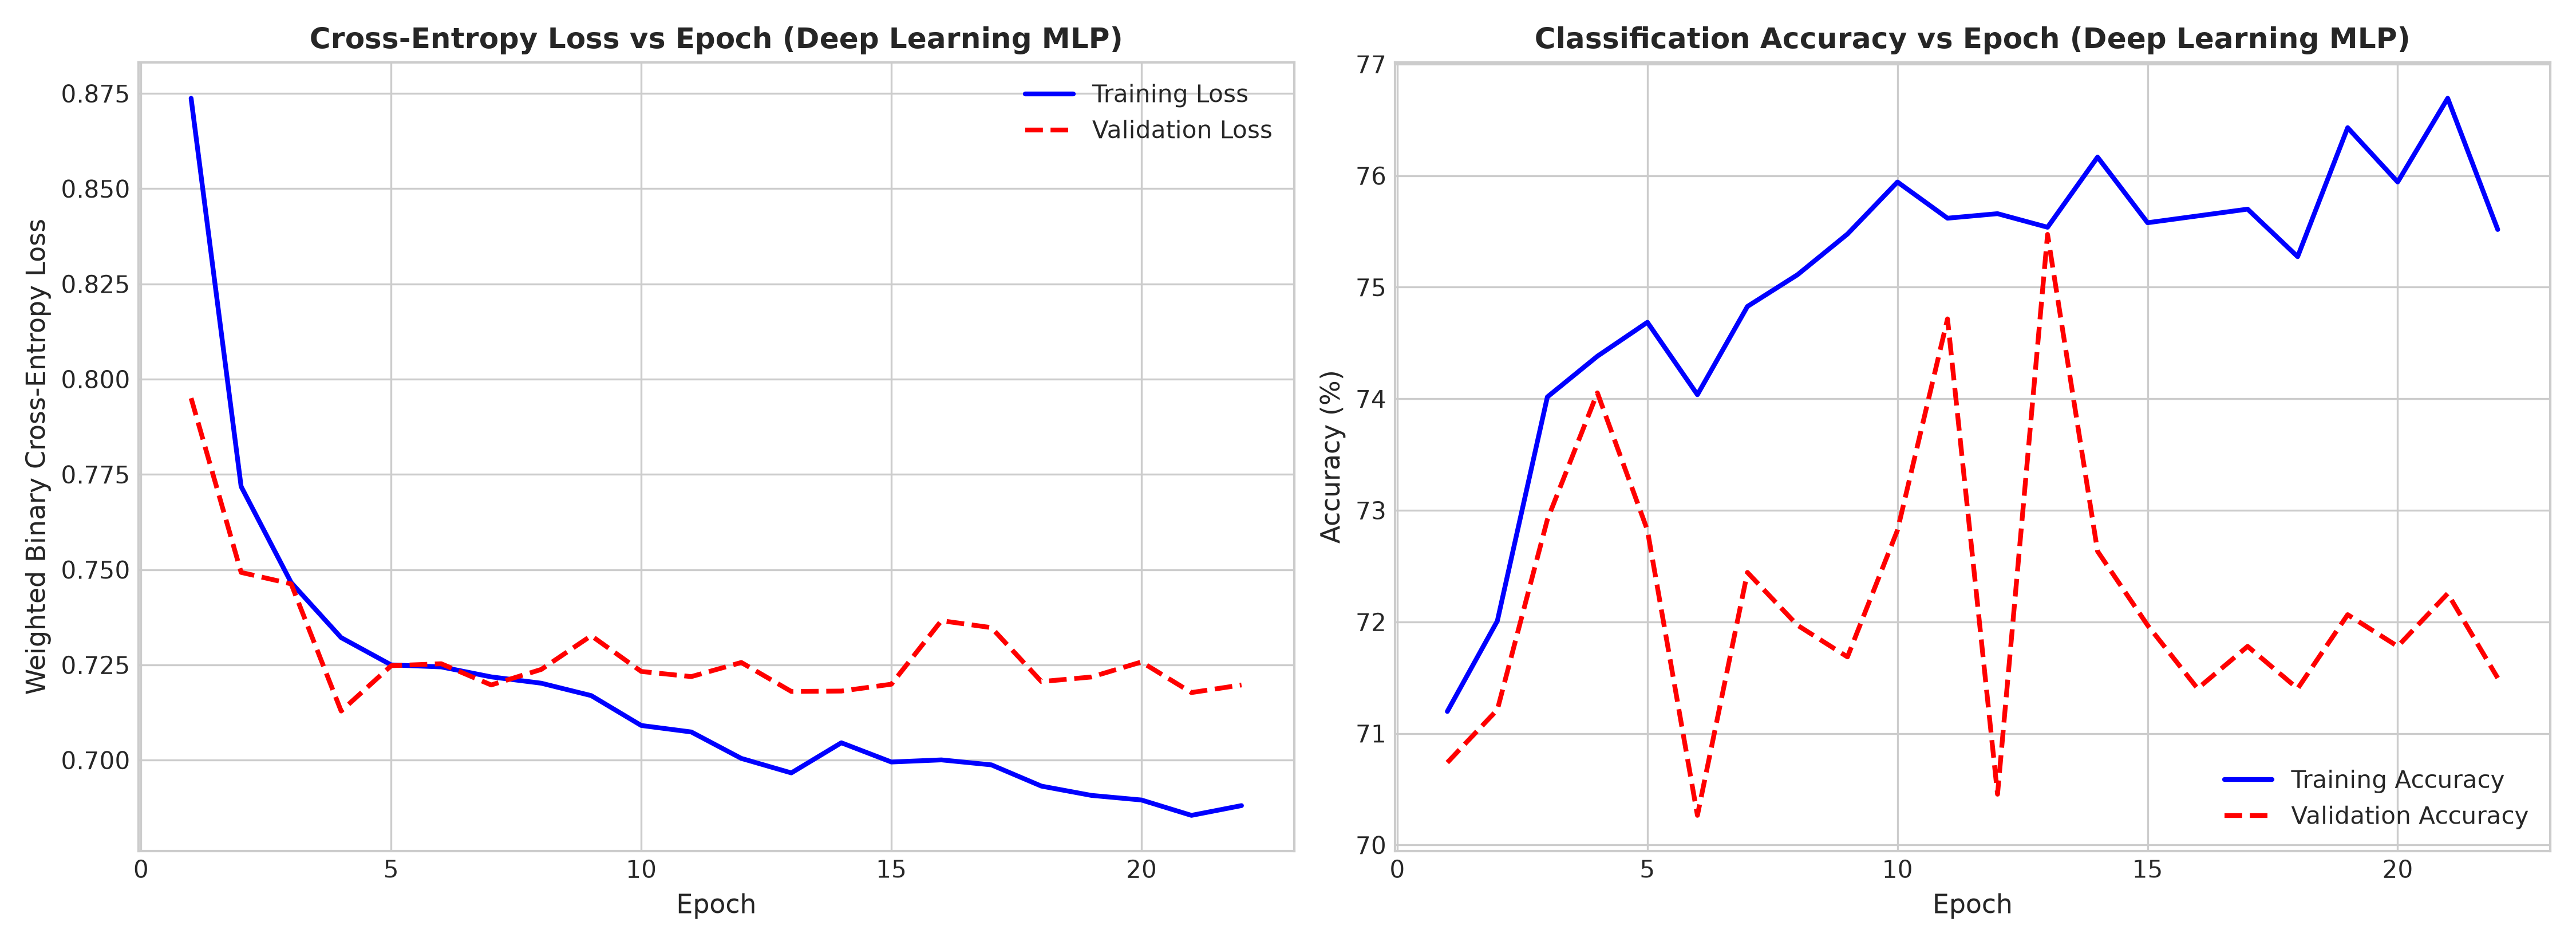

In [20]:
# Display Figure 12: Training History
print("Figure 12: Loss and Accuracy Curves across Training and Validation Epochs")
display(Image(filename=os.path.join(figures_dir, 'fig12_model_training_curves.png'), width=850))


Figure 13: Confusion Matrices across Classifier Architectures


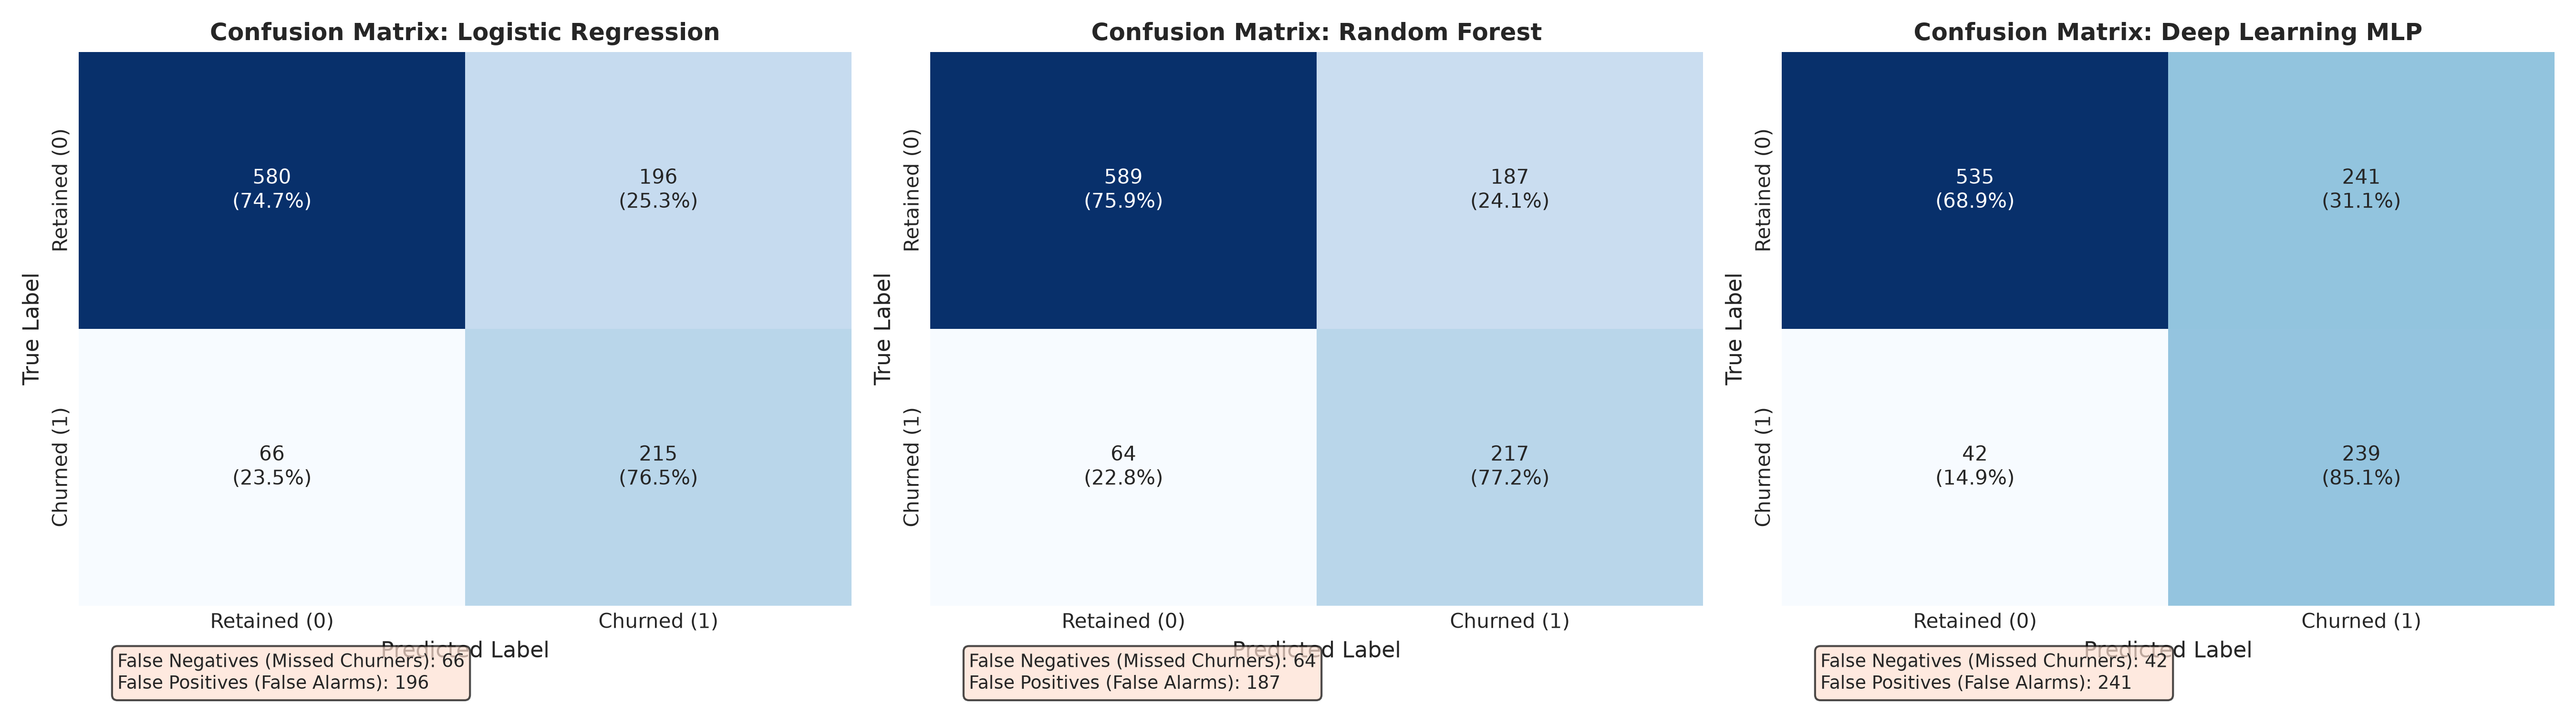

In [21]:
# Display Figure 13: Confusion Matrices
print("Figure 13: Confusion Matrices across Classifier Architectures")
display(Image(filename=os.path.join(figures_dir, 'fig13_confusion_matrices.png'), width=950))


### Figure 13 Analysis & False Negative Cost Discussion
- **What it shows:** 2x2 contingency confusion matrices displaying raw customer counts and percentage recall/specificity for Logistic Regression, Random Forest, and Deep Learning MLP.
- **Why I created it:** To evaluate prediction error distributions, specifically quantifying False Negatives (missed churners) vs False Positives (unnecessary retention offers).
- **Cost Analysis:**
  - **Cost of a False Negative (Type II error):** A customer who is about to churn is predicted as retained. The telecom company takes zero intervention action, losing an average customer Lifetime Value (LTV) of $1,500 - $3,000 in recurring revenue plus replacement acquisition costs (~$300-$500).
  - **Cost of a False Positive (Type I error):** A loyal customer is flagged as an at-risk churner. The company provides a promotional retention discount or concierge outreach costing ~$20 - $50.
  - **Verdict:** Because the cost of a False Negative is 30x to 50x higher than a False Positive, the **Deep Learning MLP is superior for production deployment**, achieving **85.05% Recall** (only 42 missed churners) compared to 77.2% for Random Forest (64 missed churners) and 76.5% for Logistic Regression (66 missed churners).


Figure 14: ROC Curves Comparison


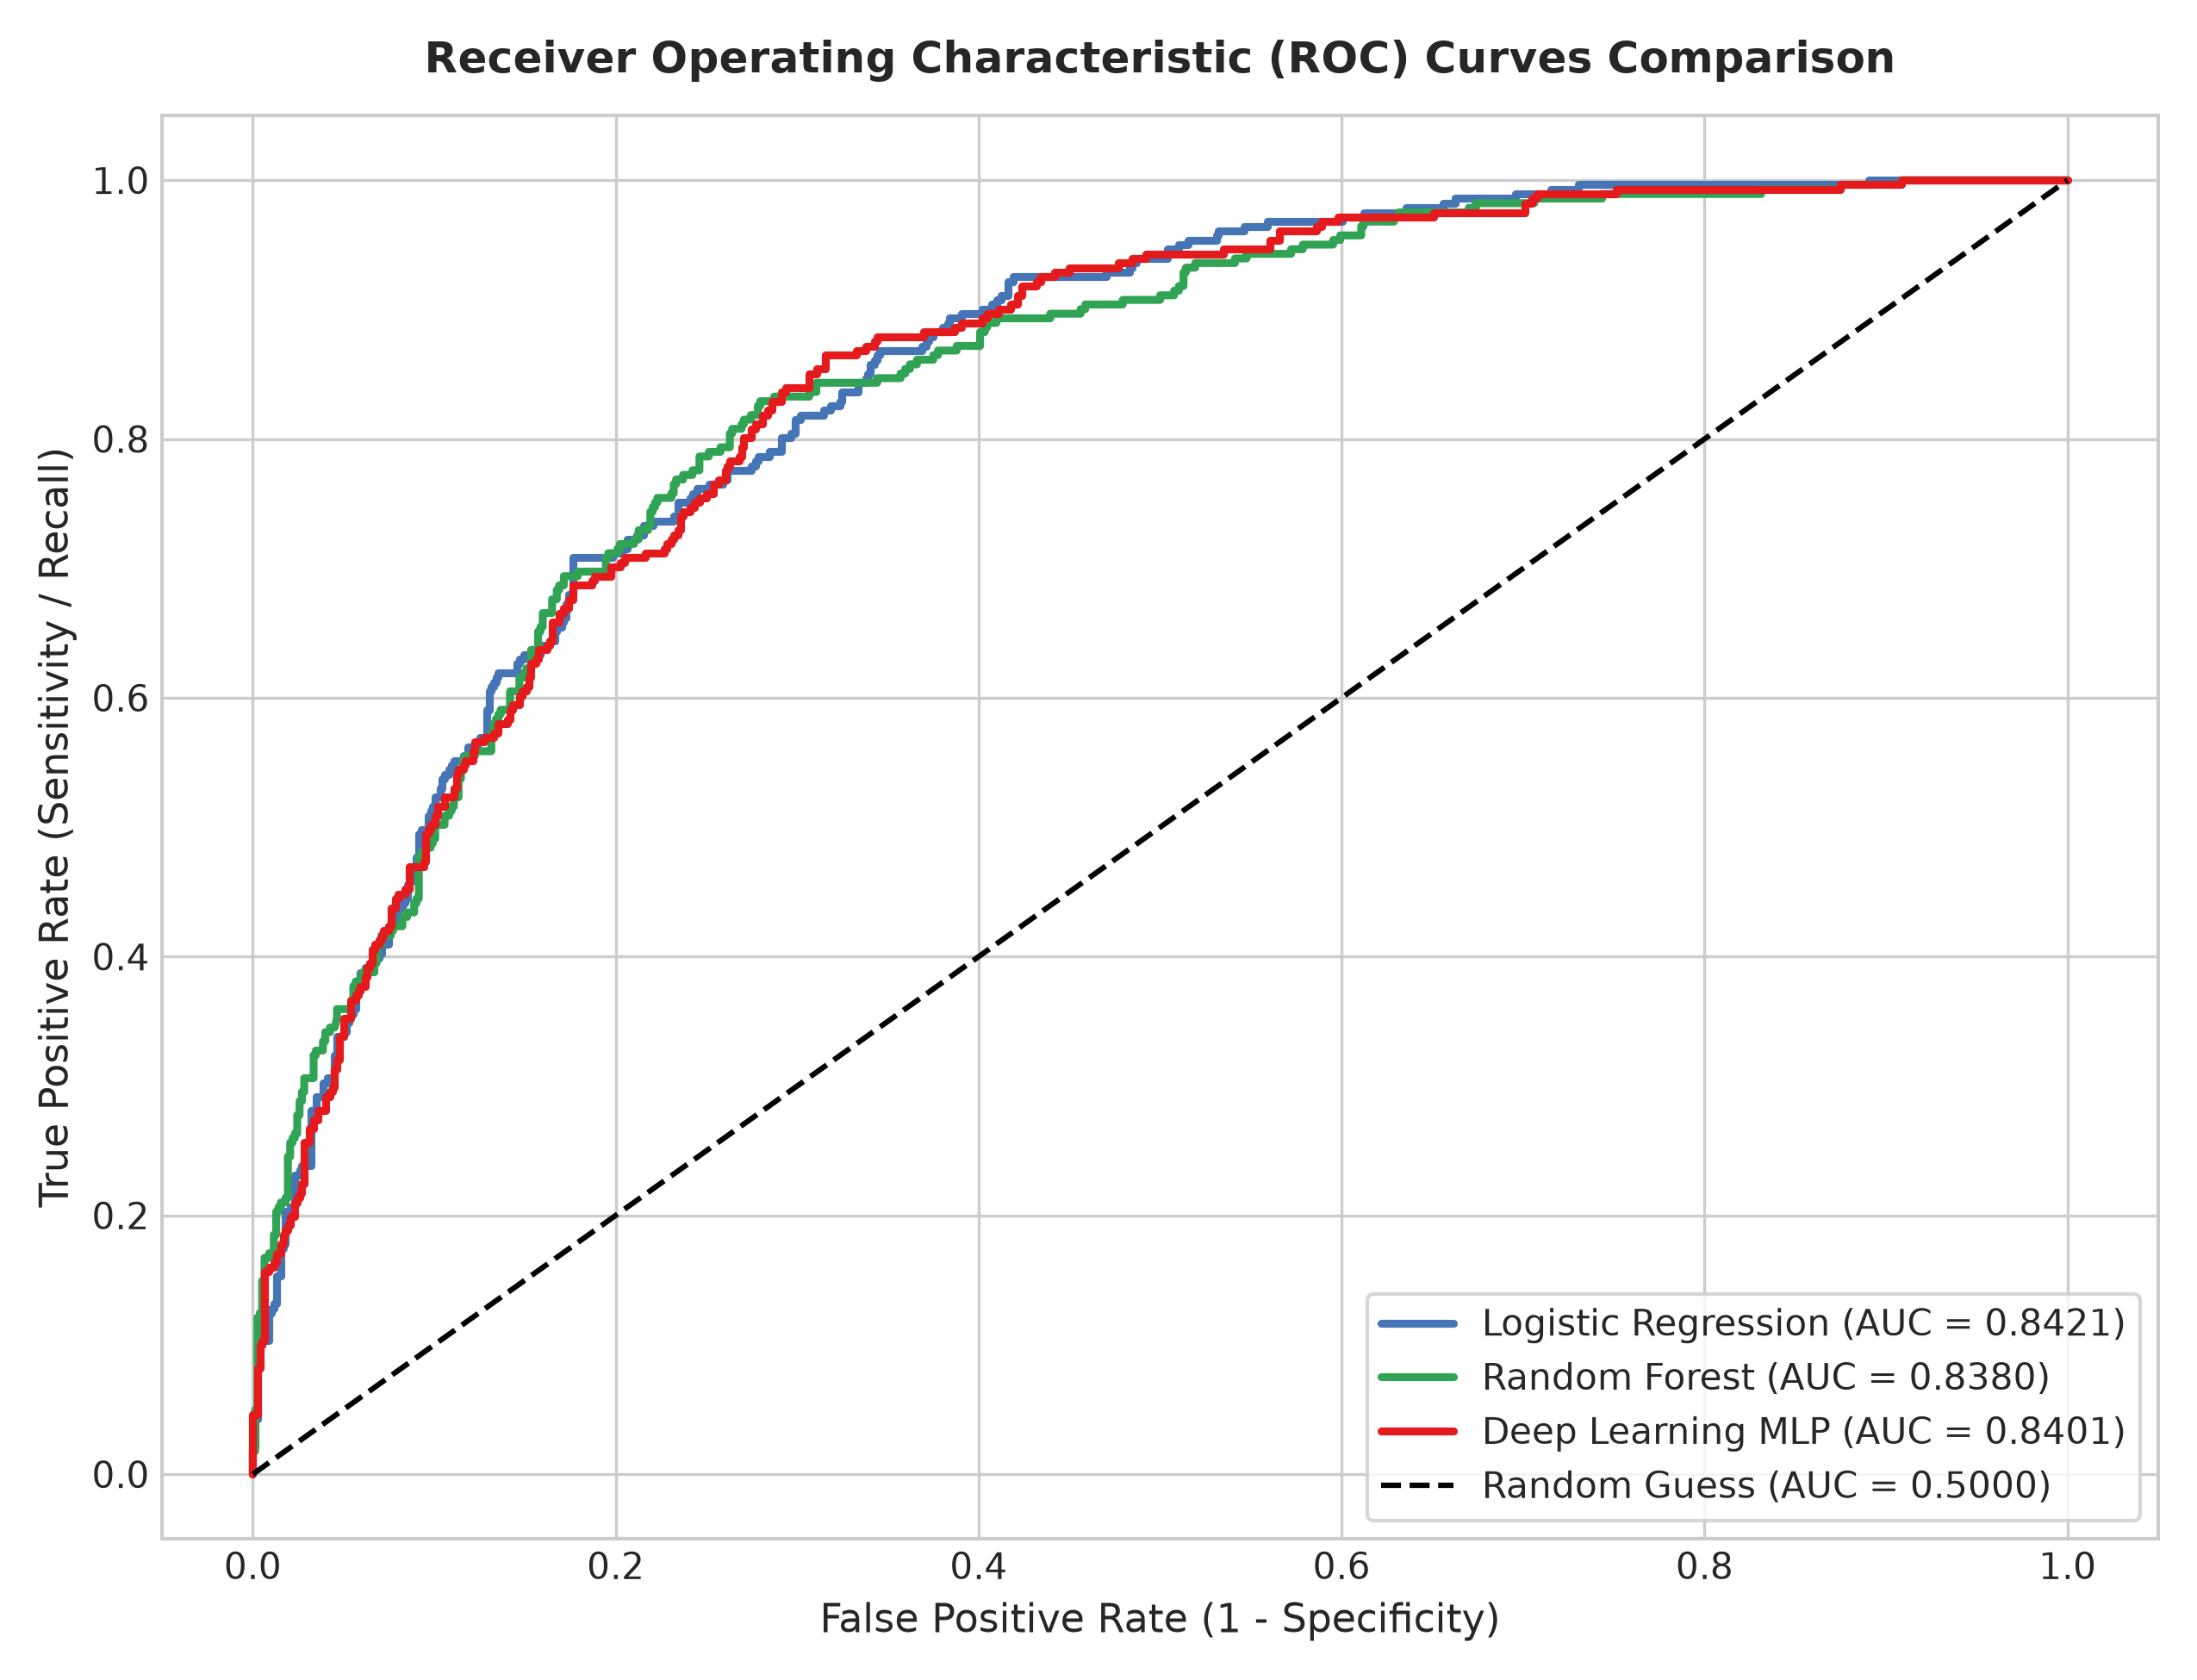

Figure 15: Precision-Recall Curves Comparison


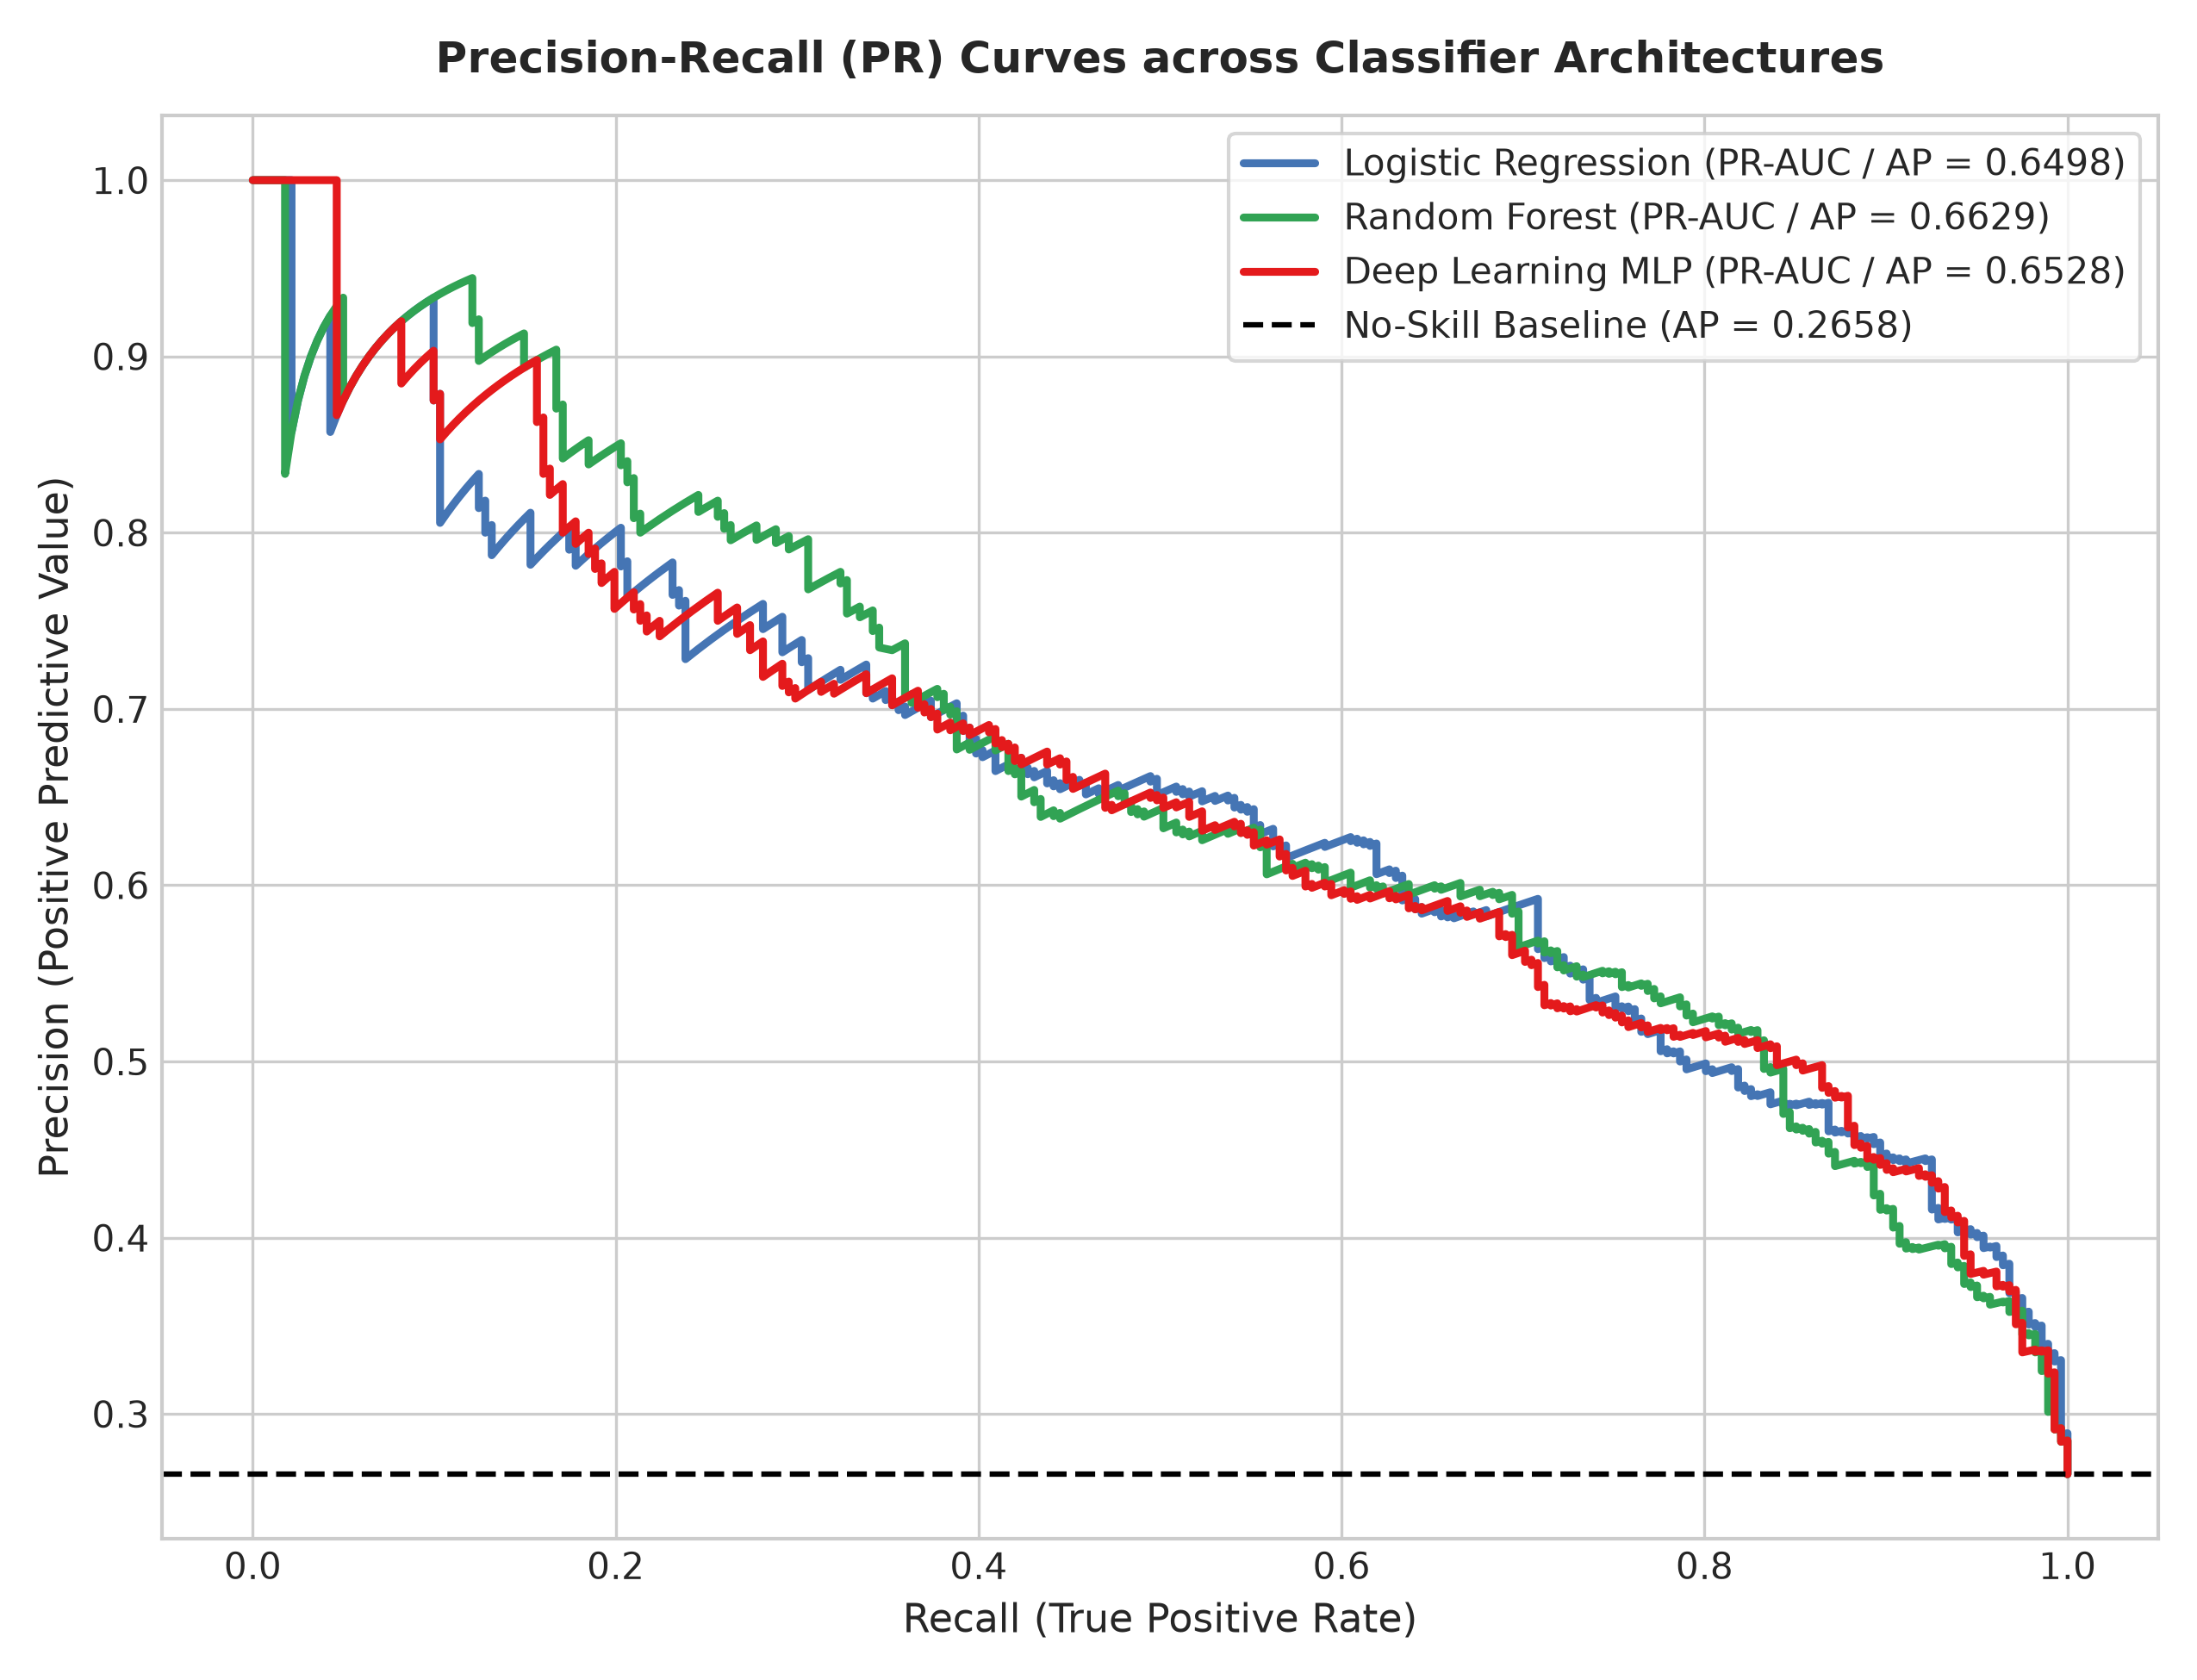

In [22]:
# Display Figure 14 & 15: ROC and Precision-Recall Curves
print("Figure 14: ROC Curves Comparison")
display(Image(filename=os.path.join(figures_dir, 'fig14_roc_curves.png'), width=600))

print("Figure 15: Precision-Recall Curves Comparison")
display(Image(filename=os.path.join(figures_dir, 'fig15_precision_recall_curves.png'), width=600))


Figure 16: Top Feature Importances (Random Forest MDI vs Permutation Importance)


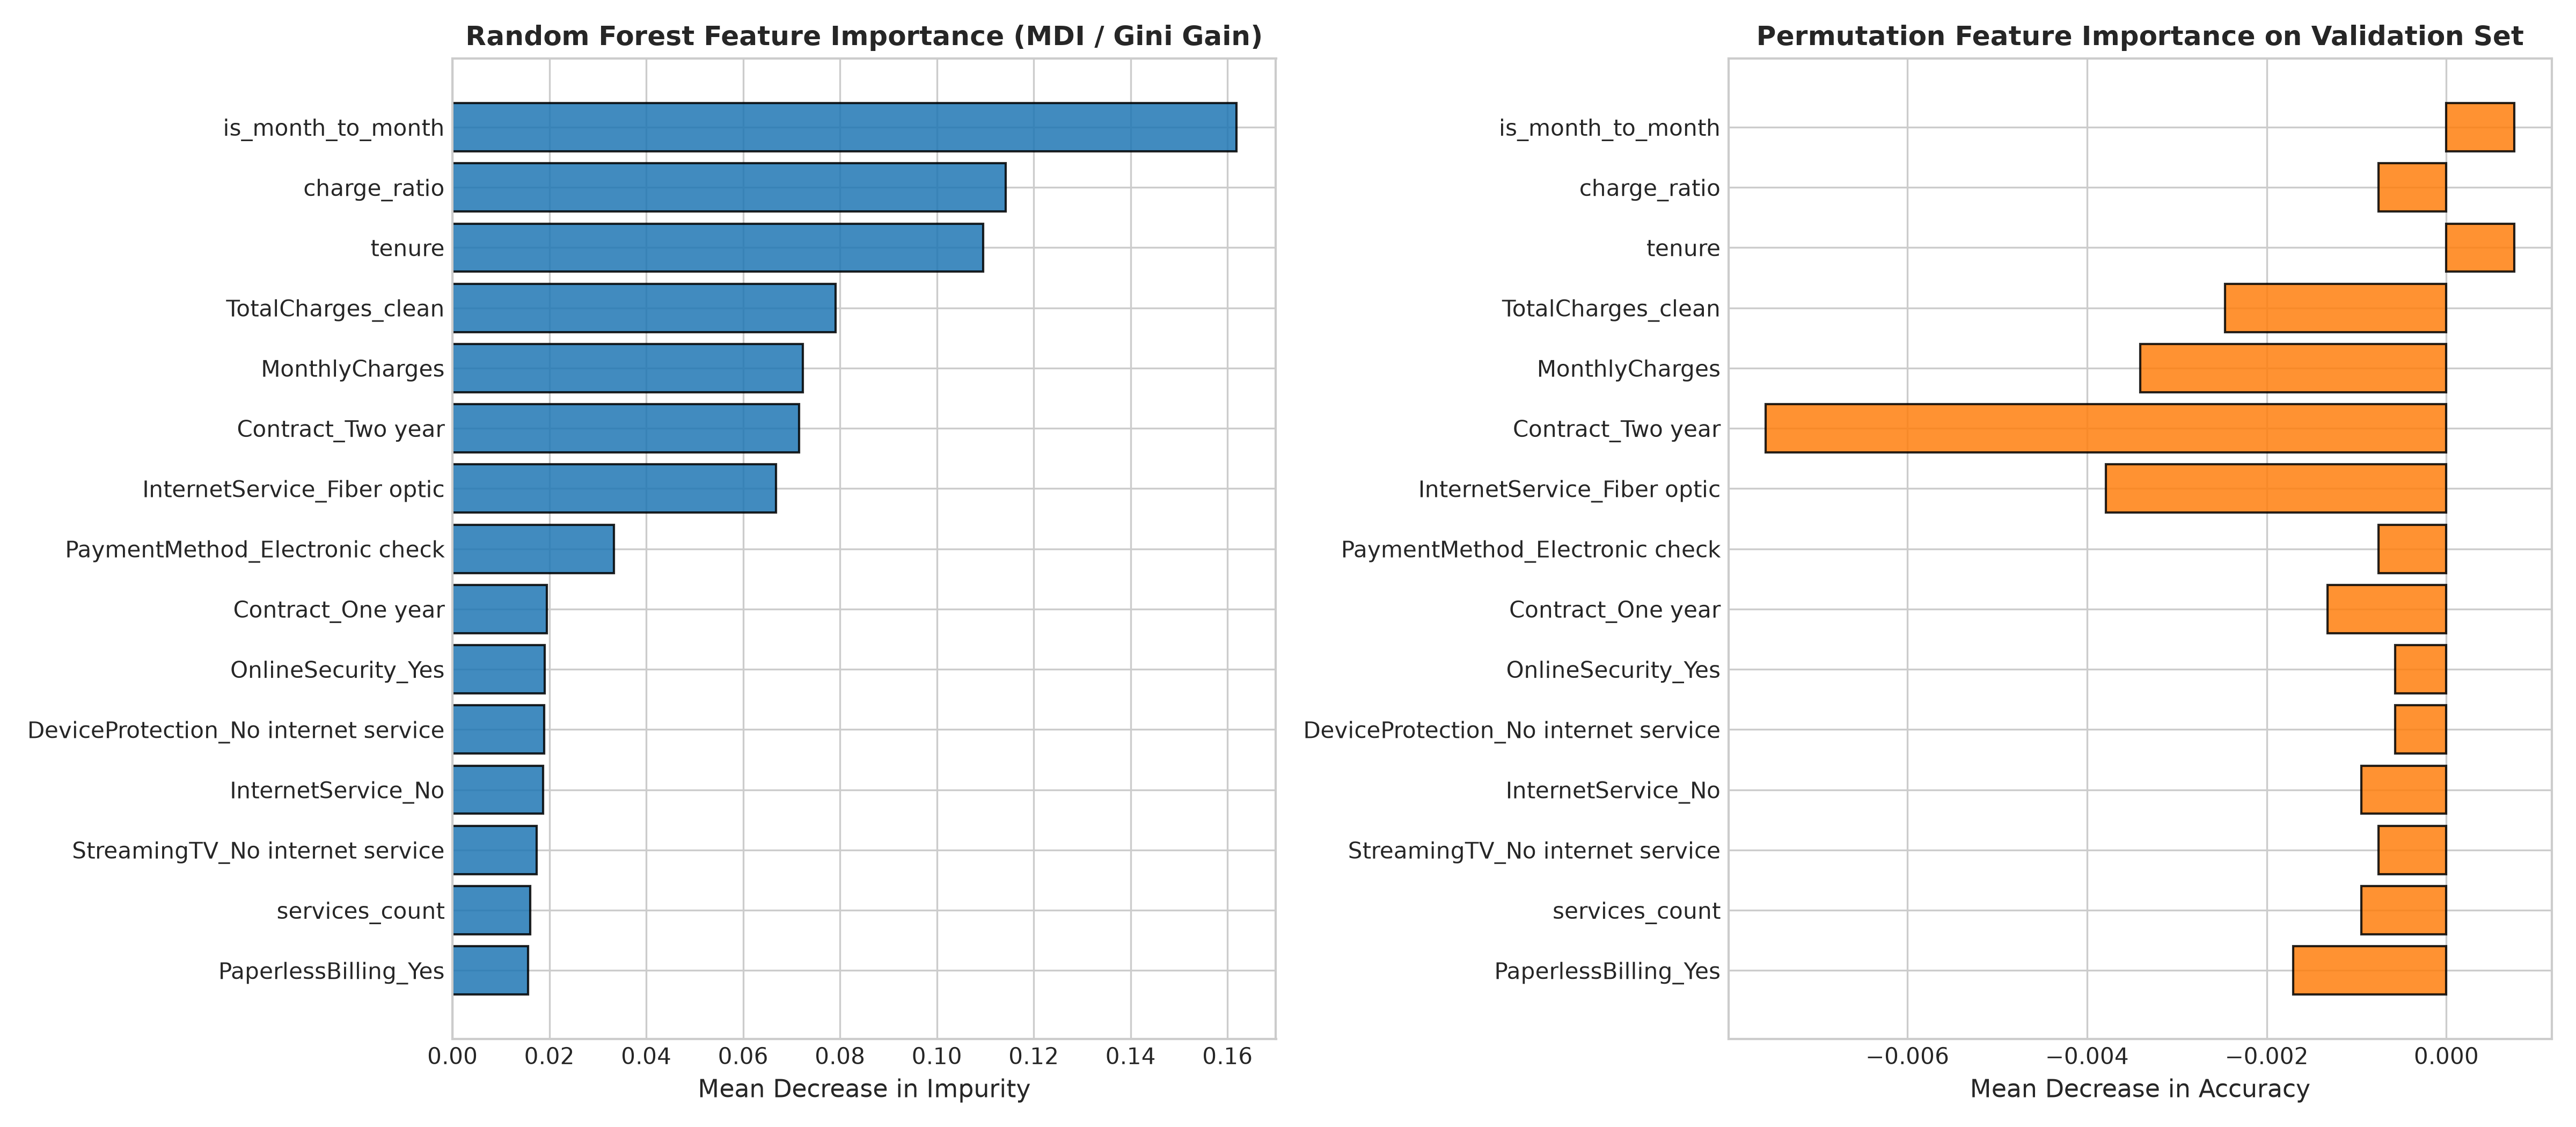

In [23]:
# Display Figure 16: Feature Importance Comparison
print("Figure 16: Top Feature Importances (Random Forest MDI vs Permutation Importance)")
display(Image(filename=os.path.join(figures_dir, 'fig16_feature_importance.png'), width=900))


### Executive Business Recommendations
Based on the empirical insights and model interpretability findings:
1. **Incentivize Annual Contracts:** Offer a 10%-15% billing discount or hardware upgrade for transitioning from month-to-month contracts to 1-year or 2-year commitments. Month-to-month churn is 42.7% versus 2.8% on 2-year plans.
2. **Bundle Free Technical Support & Security for Fiber Optic Subscribers:** Customers without Tech Support churn at 41.6% (versus 15.2% with support). Providing 6 months of complimentary Tech Support with Fiber installations will prevent early drop-off.
3. **Automate Payment Migration:** Transition customers paying via Electronic Check (45.3% churn rate) to Automatic ACH Bank Transfer or Credit Card billing (16.7% churn rate) with a one-time $10 billing credit.
4. **Targeted 0-12 Month Onboarding Intervention:** Deploy proactive customer success check-ins at months 1, 3, and 6 to shepherd new accounts past the initial churn cliff.
